# Citrus-only fine-grain stage evaluation (notebook 33b)

Notebook 33 evaluates three crops. This notebook keeps **citrus** only — the one crop
with a native BBCH scale, both levels (8 principal, 35 secondary stages), and 81 photos —
to look at the parts of the fine-grain story that the pooled view hides:

1. **Per-stage behaviour** — which citrus stages are recognised, which are never predicted,
   and where the mass goes instead (principal is well powered at ~10 photos/stage;
   secondary is sparse at ~2.3, so support is always reported).
2. **Hierarchy conditioned on the principal** — when the principal stage is right, does the
   secondary prediction improve? This is the question coarse-to-fine reranking would target.
3. **Where on the season the error lives** — ordinal error per ground-truth principal group.
4. **Language effect** — French vs English, per model.

**Scope.** The scored models are the 30 checkpoints of notebook 33: the out-of-box
baselines that its C0 setup keeps (SigLIP2 mean-pool, CLIP mean-pool/truncate,
DINOv3+BGE, random), the SigLIP2 mean-pool 0/2/4/6/8-block layer sweep, and all
DINOv3+BGE runs (out-of-box, 0/2/4/6/8-block layer sweeps, training-size and
negative-mining sweeps). The SigLIP2 max/truncate variants and the chunk-max SigLIP2
sweep are out of scope. Plot labels follow
`[architecture]_[unfrozen blocks]_[train size]` (`SigLIP2-meanpool_4L_2500`,
`DINOv3-BGE-mined_6L_5000`, …); raw encoders are `[architecture]_out-of-box`.

**Reuse.** Notebook 33b never re-encodes and never re-scores: it reads notebook 33's
outputs from `figures/` — the annotated per-photo frame (`finegrain_predictions.csv`), the
long confusion table (`finegrain_confusion.csv`), the exact chance baselines
(`finegrain_ordinal_summary.csv`), the consistency table
(`finegrain_principal_consistency.csv`), the confusion metrics
(`finegrain_confusion_metrics.csv`) and the C0 model groups (`finegrain_c0_groups.csv`,
which also carries the `model_label` column used by every figure).
Section 3 re-derives the citrus aggregates from the per-photo frame and asserts they match
those tables, so reuse never silently diverges. Run notebook 33 first.

Outputs go to `figures/citrus/` so notebook 33's files are never overwritten.


## Section 1 — Setup


In [1]:
import logging
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- paths (same resolution as notebooks 32/33) ------------------------------
ROOT = Path.cwd().parent if Path.cwd().name == "benchmark" else Path.cwd()
FIG_DIR = ROOT / "figures"                 # notebook 33 outputs = inputs here
BENCH_DIR = ROOT / "benchmark"
OUT_DIR = FIG_DIR / "citrus"               # notebook 33b outputs
OUT_DIR.mkdir(parents=True, exist_ok=True)

NB33_PRED = FIG_DIR / "finegrain_predictions.csv"
NB33_CONFUSION_LONG = FIG_DIR / "finegrain_confusion.csv"
NB33_CONFUSION_METRICS = FIG_DIR / "finegrain_confusion_metrics.csv"
NB33_ORDINAL = FIG_DIR / "finegrain_ordinal_summary.csv"
NB33_CONSISTENCY = FIG_DIR / "finegrain_principal_consistency.csv"
NB33_C0_GROUPS = FIG_DIR / "finegrain_c0_groups.csv"
STAGE_LISTS_CSV = BENCH_DIR / "stage_lists.csv"


def save_table(frame, name, index=False, preview=10):
    """Write a full DataFrame to figures/citrus/<name>.csv and preview it."""
    path = OUT_DIR / name
    frame.to_csv(path, index=index, encoding="utf-8")
    logger.info("Wrote %s (%d rows)", path, len(frame))
    print(f"Wrote {path} ({len(frame)} rows, {len(frame.columns)} columns)")
    if preview is None:
        display(frame)
    elif preview:
        display(frame.head(preview))
    return path


def save_fig(fig, name):
    """Save a figure into figures/citrus/ as a vector PDF."""
    path = OUT_DIR / f"{Path(name).stem}.pdf"
    fig.savefig(path, bbox_inches="tight")
    logger.info("Wrote %s", path)
    return path


In [2]:
LOG_FORMAT = "%(asctime)s %(levelname)s %(message)s"
logging.basicConfig(level=logging.INFO, format=LOG_FORMAT, datefmt="%H:%M:%S",
                    stream=sys.stdout, force=True)
logger = logging.getLogger("nb33b_citrus")
_handler = logging.FileHandler(ROOT / "citrus_stage_evaluation.log", encoding="utf-8")
_handler.setFormatter(logging.Formatter(LOG_FORMAT, datefmt="%H:%M:%S"))
logger.addHandler(_handler)

logger.info("Notebook 33b start: reads notebook 33's CSVs; no model load, no GPU.")
print("Inputs :", FIG_DIR)
print("Outputs:", OUT_DIR)


03:14:08 INFO Notebook 33b start: reads notebook 33's CSVs; no model load, no GPU.


Inputs : /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures
Outputs: /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus


## Section 2 — Config

Citrus only, both levels, French and English separate.

- **C0 groups** — read from notebook 33's `finegrain_c0_groups.csv` (not re-declared), so
  both notebooks always use the same (a)–(d) partition of the 30 scored models: (a)
  out-of-box encoders (SigLIP2 mean-pool, CLIP mean-pool/truncate, DINOv3+BGE,
  random), (b) SigLIP2 mean-pool with
  0/2/4/8 unfrozen blocks, (c) DINOv3+BGE with 0/2/4/6/8 unfrozen blocks, (d) DINOv3+BGE
  training size and negative mining. The groups **partition** the scored models
  (validated in Section 3), so every figure compares like with like.
- **Model labels** — read from the same table (`model_label` column). Every axis, legend
  and title shows `[architecture]_[unfrozen blocks]_[train size]`, never the internal
  checkpoint id.
- **Figure style** — same house style as notebook 33: spines off, grid `#E1E0D9`,
  palette `#2A78D6` / `#EB6834`, `dpi=150`, `bbox_inches="tight"`.


In [3]:
CROP = "citrus"
LEVELS = ("principal", "secondary")          # the order used for all level axes
LANGUAGES = ("fr", "en")
ORDINAL_TOLERANCES = [1, 2, 5, 10]           # BBCH units, for the within-Δ columns
RANK_K_VALUES = [1, 3]

# --- figure style (same house style as notebook 33) -------------------------
C0_COLOR = {"a": "#2A78D6", "b": "#EB6834", "c": "#3AA65C", "d": "#8C56B4"}
GRID_COLOR = "#E1E0D9"
FIG_DPI = 150


def style_ax(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.7)


print("crop:", CROP, "| levels:", LEVELS, "| languages:", LANGUAGES)


crop: citrus | levels: ('principal', 'secondary') | languages: ('fr', 'en')


## Section 3 — Load notebook 33's outputs and re-validate them

The per-photo frame is the source of truth; the aggregate tables are reused for the
analytic chance baselines (which need the full candidate pool) and cross-checked against
recomputed citrus aggregates.


In [4]:
missing = [p.name for p in (NB33_PRED, NB33_CONFUSION_LONG, NB33_CONFUSION_METRICS,
                            NB33_ORDINAL, NB33_CONSISTENCY, NB33_C0_GROUPS)
           if not p.exists()]
assert not missing, f"run notebook 33 first — missing {missing} in {FIG_DIR}"

ID_DTYPES = {"gt_id": str, "pred_id": str, "photo_name": str, "crop_name": str}
CONF_DTYPES = {"gt_id": str, "pred_id": str, "crop_name": str}   # no photo_name here

pred_all = pd.read_csv(NB33_PRED, dtype=ID_DTYPES)
pred = pred_all[pred_all["crop_name"] == CROP].copy()
pred["gt_principal"] = pred["gt_principal"].astype(int)
pred["pred_principal"] = pred["pred_principal"].astype(int)
pred["off_by_one"] = pred["off_by_one"].astype(bool)

conf_long = pd.read_csv(NB33_CONFUSION_LONG, dtype=CONF_DTYPES)
conf_long = conf_long[conf_long["crop_name"] == CROP].copy()
conf_metrics = pd.read_csv(NB33_CONFUSION_METRICS).query("crop_name == @CROP")
ordinal_nb33 = pd.read_csv(NB33_ORDINAL).query("crop_name == @CROP")
consistency = pd.read_csv(NB33_CONSISTENCY).query("crop_name == @CROP")

df_c0 = pd.read_csv(NB33_C0_GROUPS, dtype={"model_id": str})

# Keep only models scored consistently in every notebook-33 output. Older runs of
# notebook 33 left the two SigLIP2 max/truncate baselines in the prediction and
# confusion files while the current C0 setup excludes them; intersecting keeps the
# reuse cross-checks (cell 8) valid without rerunning notebook 33.
SCORED_MODELS = (set(pred["model_id"]) & set(conf_long["model_id"])
                 & set(conf_metrics["model_id"]) & set(ordinal_nb33["model_id"])
                 & set(consistency["model_id"]) & set(df_c0["model_id"]))
DROPPED_MODELS = sorted(set(df_c0["model_id"]) - SCORED_MODELS)
df_c0 = df_c0[df_c0["model_id"].isin(SCORED_MODELS)].copy()
C0_ORDER = list(dict.fromkeys(df_c0["c0_group"]))
C0_TITLE = df_c0.groupby("c0_group")["c0_title"].first().to_dict()
C0_MEMBERS = {g: df_c0.loc[df_c0["c0_group"] == g, "model_id"].tolist() for g in C0_ORDER}
MODEL_TO_C0 = dict(zip(df_c0["model_id"], df_c0["c0_group"]))

# publication labels from notebook 33: [architecture]_[unfrozen blocks]_[train size]
if "model_label" in df_c0.columns:
    MODEL_LABELS = dict(zip(df_c0["model_id"], df_c0["model_label"]))
else:
    MODEL_LABELS = {m: m for m in df_c0["model_id"]}
MODEL_ORDER = [m for g in C0_ORDER for m in C0_MEMBERS[g]]
MODEL_IDS = [m for m in MODEL_ORDER if m in SCORED_MODELS]

# --- scope checks ------------------------------------------------------------
# The notebook-33 model set is 30 checkpoints: the SigLIP2 mean-pool reference plus
# all DINOv3+BGE runs (the SigLIP2 max/truncate baselines are not part of it).
assert len(MODEL_IDS) == 30, f"expected 30 models, got {len(MODEL_IDS)}"
if DROPPED_MODELS:
    print(f"Ignoring {len(DROPPED_MODELS)} model(s) absent from a notebook-33 table: "
          f"{DROPPED_MODELS}")
pred = pred[pred["model_id"].isin(MODEL_IDS)].copy()
conf_long = conf_long[conf_long["model_id"].isin(MODEL_IDS)].copy()
conf_metrics = conf_metrics[conf_metrics["model_id"].isin(MODEL_IDS)].copy()
ordinal_nb33 = ordinal_nb33[ordinal_nb33["model_id"].isin(MODEL_IDS)].copy()
consistency = consistency[consistency["model_id"].isin(MODEL_IDS)].copy()
assert len(pred) == len(MODEL_IDS) * len(LEVELS) * len(LANGUAGES) * 81, len(pred)
assert sorted(pred["level"].unique()) == sorted(LEVELS)
assert sorted(pred["lang"].unique()) == sorted(LANGUAGES)
assert pred.groupby(["model_id", "level", "lang"]).size().eq(81).all()
assert int(pred["n_candidates"].max()) == 35
assert sorted(MODEL_TO_C0) == sorted(MODEL_IDS), "C0 groups and scored models disagree"

# The candidate pool comes from notebook 31's stage list (not from the confusion table,
# which only holds stages that occur as ground truth — citrus secondary stage 11 has a
# slot but no photo).
stage_lists = pd.read_csv(STAGE_LISTS_CSV, dtype={"stage_id": str, "crop_name": str})
stage_lists = stage_lists[stage_lists["crop_name"] == CROP]
POOL_SIZE = {level: int((stage_lists["level"] == level).sum()) for level in LEVELS}
for level in LEVELS:
    n_candidates = int(pred.loc[pred["level"] == level, "n_candidates"].iloc[0])
    assert POOL_SIZE[level] == n_candidates, (level, POOL_SIZE[level], n_candidates)
print(f"citrus predictions: {len(pred):,} rows "
      f"({len(MODEL_IDS)} models x {len(LEVELS)} levels x {len(LANGUAGES)} languages x 81 photos)")
print("candidate pools:", POOL_SIZE)
print("C0 groups:", {g: len(m) for g, m in C0_MEMBERS.items()})
print("figure labels:", {m: MODEL_LABELS[m] for m in MODEL_ORDER})


citrus predictions: 9,720 rows (30 models x 2 levels x 2 languages x 81 photos)
candidate pools: {'principal': 8, 'secondary': 35}
C0 groups: {'a': 5, 'b': 4, 'c': 5, 'd': 16}
figure labels: {'26_zs_siglip2_meanpool': 'SigLIP2-meanpool_out-of-box', '26_zs_clip_meanpool': 'CLIP-meanpool_out-of-box', 'zz_clip_raw': 'CLIP-truncate_out-of-box', 'zz_dinov3_bge_raw': 'DINOv3-BGE_out-of-box', 'zz_random': 'random_out-of-box', '27D_last_0': 'SigLIP2-meanpool_0L_2500', '27D_last_2': 'SigLIP2-meanpool_2L_2500', '27D_last_4': 'SigLIP2-meanpool_4L_2500', '27D_last_8': 'SigLIP2-meanpool_8L_2500', '27_last_0': 'DINOv3-BGE_0L_2500', '27_last_2': 'DINOv3-BGE_2L_2500', '27_last_4': 'DINOv3-BGE_4L_2500', '27_last_6': 'DINOv3-BGE_6L_2500', '27_last_8': 'DINOv3-BGE_8L_2500', 'smaller_size_100': 'DINOv3-BGE_6L_100', 'smaller_size_500': 'DINOv3-BGE_6L_500', 'smaller_size_1000': 'DINOv3-BGE_6L_1000', 'smaller_size_2500': 'DINOv3-BGE_6L_2500_2nd-run', 'smaller_size_5000': 'DINOv3-BGE_6L_5000', 'smaller_size_1

In [5]:
# --- cross-check the reused aggregate tables against the per-photo frame -----
def _cmp(left, right, what, tol=1e-9):
    diff = float(np.nanmax(np.abs(np.asarray(left) - np.asarray(right))))
    assert diff <= tol, f"{what}: max |diff| = {diff}"
    return diff


recomputed = []
for _, r in conf_metrics.sort_values(["model_id", "level", "lang"]).iterrows():
    sub = pred[(pred["model_id"] == r["model_id"]) & (pred["level"] == r["level"])
               & (pred["lang"] == r["lang"])]
    recomputed.append({"model_id": r["model_id"], "level": r["level"], "lang": r["lang"],
                       "N": len(sub),
                       "top1": float((sub["rank"] <= 1).mean()),
                       "mae": float(sub["ordinal_distance"].mean()),
                       "off_by_one": float(sub["off_by_one"].mean())})
df_recomp = pd.DataFrame(recomputed).sort_values(["model_id", "level", "lang"])

left = conf_metrics.sort_values(["model_id", "level", "lang"])
d_top1 = _cmp(df_recomp["top1"], left["top1_accuracy"], "R@1 vs nb33 confusion metrics")
d_off = _cmp(df_recomp["off_by_one"], left["off_by_one_rate"], "off-by-one vs nb33")

left_od = ordinal_nb33.sort_values(["model_id", "level", "lang"])
d_mae = _cmp(df_recomp["mae"], left_od["mae"], "MAE vs nb33 ordinal summary")
assert (df_recomp["N"].to_numpy() == left_od["N"].to_numpy()).all()

rec_coh = []
for _, r in consistency.sort_values(["model_id", "lang"]).iterrows():
    sub = pred[(pred["model_id"] == r["model_id"]) & (pred["level"] == "secondary")
               & (pred["lang"] == r["lang"])]
    rec_coh.append(float(sub["principal_match"].mean()))
d_coh = _cmp(np.asarray(rec_coh), consistency.sort_values(["model_id", "lang"])["coherence"],
             "coherence vs nb33 consistency")

print(f"Reuse cross-check OK — {len(df_recomp)} (model, level, lang) cells: "
      f"R@1 diff {d_top1:.1e}, MAE diff {d_mae:.1e}, off-by-one diff {d_off:.1e}, "
      f"coherence diff {d_coh:.1e}")


Reuse cross-check OK — 120 (model, level, lang) cells: R@1 diff 0.0e+00, MAE diff 0.0e+00, off-by-one diff 0.0e+00, coherence diff 0.0e+00


In [6]:
# --- citrus scope table ------------------------------------------------------
scope_rows = []
for level in LEVELS:
    sub = pred[pred["level"] == level]
    for lang in LANGUAGES:
        cell = sub[sub["lang"] == lang]
        scope_rows.append({
            "crop_name": CROP, "level": level, "lang": lang,
            "n_photos": int(cell["photo_name"].nunique()),
            "n_models": int(cell["model_id"].nunique()),
            "n_stages_in_pool": POOL_SIZE[level],
            "n_stages_with_gt": len(set(cell["gt_id"])),
            "chance_R@1": 1.0 / POOL_SIZE[level],
        })
df_scope = pd.DataFrame(scope_rows)
save_table(df_scope, "citrus_scope.csv", preview=None)


03:14:09 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_scope.csv (4 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_scope.csv (4 rows, 8 columns)


,crop_name,level,lang,n_photos,n_models,n_stages_in_pool,n_stages_with_gt,chance_R@1
0,citrus,principal,fr,81,30,8,8,0.125000
1,citrus,principal,en,81,30,8,8,0.125000
2,citrus,secondary,fr,81,30,35,34,0.028571
3,citrus,secondary,en,81,30,35,34,0.028571


PosixPath('/mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_scope.csv')

## Section 4 — Citrus headline table

One row per `(model, level, lang)` with the ranking metrics derived from the reused
per-photo ranks (R@1, R@3, MRR — including the principal level, which only citrus has) and
the distance/consistency metrics. `chance_mae`, `chance_within_*` and `spearman_rho` are
taken verbatim from notebook 33's ordinal summary, because the exact chance baseline needs
the full candidate pool.


In [7]:
CHANCE_COLS = (["chance_mae"] + [f"chance_within_{d}" for d in ORDINAL_TOLERANCES]
               + ["spearman_rho"])
chance_lookup = ordinal_nb33.set_index(["model_id", "level", "lang"])[CHANCE_COLS]
coh_lookup = consistency.set_index(["model_id", "lang"])

rows = []
for model_id in MODEL_IDS:
    for level in LEVELS:
        K = POOL_SIZE[level]
        for lang in LANGUAGES:
            sub = pred[(pred["model_id"] == model_id) & (pred["level"] == level)
                       & (pred["lang"] == lang)]
            rank = sub["rank"].to_numpy(dtype=float)
            dist = sub["ordinal_distance"].to_numpy(dtype=float)
            row = {
                "model_id": model_id, "c0_group": MODEL_TO_C0[model_id],
                "crop_name": CROP, "level": level, "lang": lang,
                "N": len(sub), "n_candidates": K,
                "R@1": float((rank <= 1).mean()), "R@3": float((rank <= 3).mean()),
                "MRR": float((1.0 / rank).mean()),
                "chance_R@1": 1.0 / K, "chance_R@3": min(3, K) / K,
                "chance_MRR": sum(1.0 / i for i in range(1, K + 1)) / K,
                "mae": float(dist.mean()), "median_distance": float(np.median(dist)),
                "signed_bias": float(sub["signed_distance"].mean()),
                "off_by_one_rate": float(sub["off_by_one"].mean()),
            }
            for d in ORDINAL_TOLERANCES:
                row[f"within_{d}"] = float((dist <= d).mean())
            row.update({c: float(chance_lookup.loc[(model_id, level, lang), c])
                        for c in CHANCE_COLS})
            # coherence is a secondary-level property; level agreement pairs the two levels
            row["coherence"] = (float(coh_lookup.loc[(model_id, lang), "coherence"])
                                if level == "secondary" else np.nan)
            row["chance_coherence"] = (float(coh_lookup.loc[(model_id, lang), "chance_coherence"])
                                       if level == "secondary" else np.nan)
            row["level_agreement"] = (float(coh_lookup.loc[(model_id, lang), "level_agreement"])
                                      if level == "secondary" else np.nan)
            row["chance_agreement"] = (float(coh_lookup.loc[(model_id, lang), "chance_agreement"])
                                       if level == "secondary" else np.nan)
            rows.append(row)

SUMMARY_COLS = ["model_id", "c0_group", "crop_name", "level", "lang", "N", "n_candidates",
                "R@1", "R@3", "MRR", "chance_R@1", "chance_R@3", "chance_MRR",
                "mae", "median_distance", "signed_bias", "off_by_one_rate",
                "within_1", "within_2", "within_5", "within_10",
                "chance_mae", "chance_within_1", "chance_within_2", "chance_within_5",
                "chance_within_10", "spearman_rho", "coherence", "chance_coherence",
                "level_agreement", "chance_agreement"]
df_summary = pd.DataFrame(rows)[SUMMARY_COLS]
save_table(df_summary, "citrus_summary.csv", preview=0)

print("Best per (level, lang):")
for level in LEVELS:
    for lang in LANGUAGES:
        block = df_summary[(df_summary["level"] == level) & (df_summary["lang"] == lang)]
        best = block.loc[block["R@1"].idxmax()]
        low = block.loc[block["mae"].idxmin()]
        print(f"  {level:9s} {lang}  R@1 {best['R@1']:.3f} ({best['model_id']})"
              f"  |  MAE {low['mae']:5.2f} ({low['model_id']}); chance {low['chance_mae']:.2f}")
display(df_summary.sort_values(["level", "lang", "R@1"],
                               ascending=[True, True, False]).head(10))


03:14:10 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_summary.csv (120 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_summary.csv (120 rows, 31 columns)
Best per (level, lang):
  principal fr  R@1 0.432 (27_last_8)  |  MAE  1.21 (27_last_8); chance 3.24
  principal en  R@1 0.370 (smaller_size_10000)  |  MAE  1.77 (26_zs_siglip2_meanpool); chance 3.24
  secondary fr  R@1 0.123 (29_sweep_size_5000)  |  MAE 18.69 (26_zs_clip_meanpool); chance 31.78
  secondary en  R@1 0.111 (27_last_4)  |  MAE 18.06 (27_last_4); chance 31.78


,model_id,c0_group,crop_name,level,lang,N,n_candidates,R@1,R@3,MRR,...,chance_mae,chance_within_1,chance_within_2,chance_within_5,chance_within_10,spearman_rho,coherence,chance_coherence,level_agreement,chance_agreement
77,smaller_size_10000,d,citrus,principal,en,81,8,0.370370,0.654321,0.547237,...,3.242284,0.29784,0.458333,0.79784,1.0,0.305993,NaN,NaN,NaN,NaN
69,smaller_size_2500,d,citrus,principal,en,81,8,0.358025,0.592593,0.530291,...,3.242284,0.29784,0.458333,0.79784,1.0,0.238709,NaN,NaN,NaN,NaN
81,smaller_size_20000,d,citrus,principal,en,81,8,0.358025,0.666667,0.555085,...,3.242284,0.29784,0.458333,0.79784,1.0,0.430002,NaN,NaN,NaN,NaN
1,26_zs_siglip2_meanpool,a,citrus,principal,en,81,8,0.333333,0.567901,0.499838,...,3.242284,0.29784,0.458333,0.79784,1.0,0.441195,NaN,NaN,NaN,NaN
49,27_last_6,c,citrus,principal,en,81,8,0.333333,0.592593,0.520414,...,3.242284,0.29784,0.458333,0.79784,1.0,0.233152,NaN,NaN,NaN,NaN
53,27_last_8,c,citrus,principal,en,81,8,0.333333,0.641975,0.532760,...,3.242284,0.29784,0.458333,0.79784,1.0,0.533897,NaN,NaN,NaN,NaN
105,29_sweep_size_5000,d,citrus,principal,en,81,8,0.320988,0.518519,0.498163,...,3.242284,0.29784,0.458333,0.79784,1.0,0.174332,NaN,NaN,NaN,NaN
5,26_zs_clip_meanpool,a,citrus,principal,en,81,8,0.296296,0.604938,0.493533,...,3.242284,0.29784,0.458333,0.79784,1.0,0.403067,NaN,NaN,NaN,NaN
9,zz_clip_raw,a,citrus,principal,en,81,8,0.296296,0.604938,0.493533,...,3.242284,0.29784,0.458333,0.79784,1.0,0.403067,NaN,NaN,NaN,NaN
33,27D_last_8,b,citrus,principal,en,81,8,0.296296,0.555556,0.487155,...,3.242284,0.29784,0.458333,0.79784,1.0,0.381819,NaN,NaN,NaN,NaN


In [8]:
def pool_ids(level):
    """All citrus pool ids in BBCH order. Citrus ids are native BBCH, so int(id) is the
    ordinal; unlike the confusion table this keeps stages that have no photo."""
    ids = stage_lists.loc[stage_lists["level"] == level, "stage_id"].astype(str).tolist()
    return sorted(ids, key=int)


def stage_rows(model_id, level, lang):
    sub = pred[(pred["model_id"] == model_id) & (pred["level"] == level)
               & (pred["lang"] == lang)]
    out = []
    for sid in pool_ids(level):
        gt = sub[sub["gt_id"] == sid]
        hit = gt[gt["pred_id"] == sid]
        preds = sub[sub["pred_id"] == sid]
        wrong = gt[gt["pred_id"] != sid]["pred_id"]
        out.append({
            "model_id": model_id, "c0_group": MODEL_TO_C0[model_id],
            "level": level, "lang": lang, "stage_id": sid,
            "ordinal": float(gt["gt_ordinal"].iloc[0]) if len(gt) else float(int(sid)),
            "support": len(gt),
            "recall": float(len(hit) / len(gt)) if len(gt) else np.nan,
            "precision": float(len(hit) / len(preds)) if len(preds) else np.nan,
            "mean_distance": float(gt["ordinal_distance"].mean()) if len(gt) else np.nan,
            "most_common_wrong": (wrong.value_counts().index[0]
                                  if len(wrong) else ""),
        })
    return out


stage_records = []
for model_id in MODEL_IDS:
    for level in LEVELS:
        for lang in LANGUAGES:
            stage_records.extend(stage_rows(model_id, level, lang))
df_stage = pd.DataFrame(stage_records)
save_table(df_stage, "citrus_per_stage.csv", preview=0)

print("Principal stages, worst mean recall across models:")
piv = (df_stage[(df_stage["level"] == "principal") & (df_stage["lang"] == "fr")]
       .pivot_table(index="stage_id", values="recall", aggfunc="mean")
       .sort_values("recall"))
display(piv)

no_photo = (df_stage[(df_stage["level"] == "secondary") & (df_stage["support"] == 0)]
            ["stage_id"].unique().tolist())
print(f"Secondary stages with no ground-truth photo (not scored): {no_photo}")
never = (df_stage[(df_stage["level"] == "secondary")]
         .groupby("stage_id")["precision"].max())
print(f"Secondary stages never predicted by ANY model: "
      f"{int(never.isna().sum())} of {len(never)}")


03:14:12 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_per_stage.csv (2580 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_per_stage.csv (2580 rows, 11 columns)
Principal stages, worst mean recall across models:


,recall
stage_id,
0,0.033333
9,0.100000
3,0.144444
5,0.194444
7,0.212500
1,0.216667
8,0.309091
6,0.394444


Secondary stages with no ground-truth photo (not scored): ['11']
Secondary stages never predicted by ANY model: 0 of 35


## Section 6 — Hierarchy conditioned on the principal prediction

Join each photo's principal-level row to its secondary-level row and ask: **does the
secondary top-1 improve when the principal top-1 is already correct?** This is the headroom
coarse-to-fine reranking would exploit — if it is small, reranking cannot help.
`sibling_rate` is the fraction of secondary top-1s that land in the correct principal
family, which can be high even when the exact stage is wrong.


In [9]:
pri = (pred[pred["level"] == "principal"]
       [["model_id", "lang", "photo_name", "rank", "pred_id", "gt_principal"]]
       .rename(columns={"rank": "rank_pri", "pred_id": "pred_pri"}))
sec = (pred[pred["level"] == "secondary"]
       [["model_id", "lang", "photo_name", "rank", "pred_id", "principal_match"]]
       .rename(columns={"rank": "rank_sec", "pred_id": "pred_sec"}))
pairs = pri.merge(sec, on=["model_id", "lang", "photo_name"], validate="one_to_one")
pairs["pri_ok"] = pairs["rank_pri"] == 1
pairs["sec_ok"] = pairs["rank_sec"] == 1
assert len(pairs) == len(MODEL_IDS) * len(LANGUAGES) * 81

hier_rows = []
for model_id in MODEL_IDS:
    for lang in LANGUAGES:
        m = pairs[(pairs["model_id"] == model_id) & (pairs["lang"] == lang)]
        ok, bad = m[m["pri_ok"]], m[~m["pri_ok"]]
        hier_rows.append({
            "model_id": model_id, "c0_group": MODEL_TO_C0[model_id], "lang": lang,
            "n": len(m), "n_pri_correct": len(ok), "n_pri_wrong": len(bad),
            "sec_R@1": float(m["sec_ok"].mean()),
            "sec_R@1_given_pri_correct": float(ok["sec_ok"].mean()) if len(ok) else np.nan,
            "sec_R@1_given_pri_wrong": float(bad["sec_ok"].mean()) if len(bad) else np.nan,
            "sibling_rate": float(m["principal_match"].mean()),
            "sibling_rate_given_pri_correct": (float(ok["principal_match"].mean())
                                               if len(ok) else np.nan),
            "sibling_rate_given_pri_wrong": (float(bad["principal_match"].mean())
                                             if len(bad) else np.nan),
            "chance_sec_R@1": 1.0 / POOL_SIZE["secondary"],
        })
df_hier = pd.DataFrame(hier_rows)
save_table(df_hier, "citrus_hierarchy.csv", preview=0)

print("Hierarchy, averaged over models (fr/en):")
for lang in LANGUAGES:
    m = df_hier[df_hier["lang"] == lang]
    print(f"  {lang}: secondary R@1 {m['sec_R@1'].mean():.3f} | "
          f"given principal correct {m['sec_R@1_given_pri_correct'].mean():.3f} | "
          f"given principal wrong {m['sec_R@1_given_pri_wrong'].mean():.3f} | "
          f"sibling rate {m['sibling_rate'].mean():.3f}")
display(df_hier.sort_values("sec_R@1_given_pri_correct", ascending=False).head(8))


03:14:12 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_hierarchy.csv (60 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_hierarchy.csv (60 rows, 13 columns)
Hierarchy, averaged over models (fr/en):
  fr: secondary R@1 0.056 | given principal correct 0.102 | given principal wrong 0.044 | sibling rate 0.247
  en: secondary R@1 0.055 | given principal correct 0.082 | given principal wrong 0.046 | sibling rate 0.244


,model_id,c0_group,lang,n,n_pri_correct,n_pri_wrong,sec_R@1,sec_R@1_given_pri_correct,sec_R@1_given_pri_wrong,sibling_rate,sibling_rate_given_pri_correct,sibling_rate_given_pri_wrong,chance_sec_R@1
40,smaller_size_20000,d,fr,81,23,58,0.111111,0.304348,0.034483,0.308642,0.521739,0.224138,0.028571
23,27_last_4,c,en,81,17,64,0.111111,0.294118,0.062500,0.358025,0.647059,0.281250,0.028571
30,smaller_size_500,d,fr,81,8,73,0.061728,0.250000,0.041096,0.135802,0.250000,0.123288,0.028571
38,smaller_size_10000,d,fr,81,17,64,0.074074,0.235294,0.031250,0.246914,0.529412,0.171875,0.028571
31,smaller_size_500,d,en,81,17,64,0.086420,0.235294,0.046875,0.209877,0.294118,0.187500,0.028571
50,29_sweep_size_2500,d,fr,81,14,67,0.074074,0.214286,0.044776,0.333333,0.642857,0.268657,0.028571
35,smaller_size_2500,d,en,81,29,52,0.111111,0.206897,0.057692,0.370370,0.517241,0.288462,0.028571
49,29_sweep_size_1000,d,en,81,17,64,0.086420,0.176471,0.062500,0.185185,0.294118,0.156250,0.028571


## Section 7 — Where on the season the error lives

Secondary predictions grouped by the **ground-truth principal** (0 = dormancy/bud break …
9 = senescence), per model and language: support, R@1, ordinal MAE and signed bias. This
separates "hard because the stage is ambiguous" from "hard because that part of the season
was rarely seen".


In [10]:
season_rows = []
for model_id in MODEL_IDS:
    for lang in LANGUAGES:
        sub = pred[(pred["model_id"] == model_id) & (pred["level"] == "secondary")
                   & (pred["lang"] == lang)]
        for g, grp in sub.groupby("gt_principal"):
            season_rows.append({
                "model_id": model_id, "c0_group": MODEL_TO_C0[model_id], "lang": lang,
                "gt_principal": int(g), "N": len(grp),
                "R@1": float((grp["rank"] <= 1).mean()),
                "mae": float(grp["ordinal_distance"].mean()),
                "signed_bias": float(grp["signed_distance"].mean()),
                "sibling_rate": float(grp["principal_match"].mean()),
            })
df_season = pd.DataFrame(season_rows).sort_values(["model_id", "lang", "gt_principal"])
save_table(df_season, "citrus_error_by_principal.csv", preview=0)

ref_id = (df_summary[(df_summary["level"] == "secondary") & (df_summary["lang"] == "fr")]
          .sort_values("mae").iloc[0]["model_id"])
ref = df_season[(df_season["model_id"] == ref_id) & (df_season["lang"] == "fr")]
print(f"Reference model {ref_id} · fr (lowest citrus secondary MAE), by ground-truth principal:")
display(ref[["gt_principal", "N", "R@1", "mae", "signed_bias"]].reset_index(drop=True))


03:14:12 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_error_by_principal.csv (480 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_error_by_principal.csv (480 rows, 9 columns)
Reference model 26_zs_clip_meanpool · fr (lowest citrus secondary MAE), by ground-truth principal:


,gt_principal,N,R@1,mae,signed_bias
0,0,9,0.000000,47.666667,47.666667
1,1,6,0.000000,42.500000,42.500000
2,3,6,0.000000,19.666667,19.666667
3,5,18,0.055556,9.666667,4.555556
4,6,18,0.000000,11.888889,-8.222222
5,7,8,0.000000,10.250000,-6.000000
6,8,11,0.181818,6.909091,-6.545455
7,9,5,0.000000,33.200000,-33.200000


## Section 8 — Language effect

French and English stage descriptions are different text; the delta is per model and level.
A consistent sign across models means the difference is a property of the descriptions, not
of one model's training.


In [11]:
delta_rows = []
for model_id in MODEL_IDS:
    for level in LEVELS:
        fr = df_summary[(df_summary["model_id"] == model_id) & (df_summary["level"] == level)
                        & (df_summary["lang"] == "fr")].iloc[0]
        en = df_summary[(df_summary["model_id"] == model_id) & (df_summary["level"] == level)
                        & (df_summary["lang"] == "en")].iloc[0]
        delta_rows.append({
            "model_id": model_id, "c0_group": MODEL_TO_C0[model_id], "level": level,
            "R@1_fr": float(fr["R@1"]), "R@1_en": float(en["R@1"]),
            "R@1_delta_fr_minus_en": float(fr["R@1"] - en["R@1"]),
            "mae_fr": float(fr["mae"]), "mae_en": float(en["mae"]),
            "mae_delta_fr_minus_en": float(fr["mae"] - en["mae"]),
        })
df_lang = pd.DataFrame(delta_rows)
save_table(df_lang, "citrus_language_delta.csv", preview=0)

for level in LEVELS:
    block = df_lang[df_lang["level"] == level]
    pos = int((block["R@1_delta_fr_minus_en"] > 0).sum())
    print(f"{level:9s}: fr > en on R@1 for {pos}/{len(block)} models | "
          f"mean Δ R@1 = {block['R@1_delta_fr_minus_en'].mean():+.3f} | "
          f"mean Δ MAE = {block['mae_delta_fr_minus_en'].mean():+.2f} BBCH")


03:14:12 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_language_delta.csv (60 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_language_delta.csv (60 rows, 9 columns)
principal: fr > en on R@1 for 14/30 models | mean Δ R@1 = -0.010 | mean Δ MAE = -0.12 BBCH
secondary: fr > en on R@1 for 13/30 models | mean Δ R@1 = +0.002 | mean Δ MAE = -0.85 BBCH


## Section 9 — Plots

Matplotlib only, same house style as notebook 33 (spines off, grid `#E1E0D9`,
palette `#2A78D6` / `#EB6834`), `dpi=150`, `bbox_inches="tight"`.

Every figure uses the same **C0 model-comparison setup** as notebook 33, read from
`finegrain_c0_groups.csv`:

| C0 | comparison | shown in |
| -- | ---------- | -------- |
| (a) | out-of-box encoders — the NB26 baselines kept in the 30-checkpoint set (SigLIP2 mean-pool, CLIP mean-pool/truncate, DINOv3+BGE, random) | every grouped figure; `citrus_r1_mae_by_model.pdf` |
| (b) | SigLIP2 mean-pool with 0 / 2 / 4 / 8 unfrozen blocks | every grouped figure |
| (c) | DINOv3+BGE with 0 / 2 / 4 / 6 / 8 unfrozen blocks | every grouped figure |
| (d) | DINOv3+BGE training size and negative mining (NB28 vs NB29, 6 blocks) | every grouped figure |

Grouped figures put the models in C0 order with `(a)`–`(d)` separators, and each group's
best model (by the figure's metric) is the one used in the per-stage and confusion panels.
Model identifiers in every axis, legend and title are the publication labels of Section 2
(`[architecture]_[unfrozen blocks]_[train size]`), never the internal checkpoint ids.

**14 vector PDF figures total**, written to `figures/citrus/`: R@1/MAE bars,
family-restricted ordinal MAE (full family view plus two compact two-checkpoint
versions, with four and five reference baselines), paired OOB vs best-fine-tuned
comparisons, difficulty extremes (hardest/easiest photos and stages), CDF of the top-1
absolute BBCH-code error, per-stage recall (principal and secondary), principal and
secondary confusion, hierarchy, error by ground-truth principal, and the language
delta.


In [12]:
def c0_axis_order(values, ascending=True):
    """(model order, {group: (start, stop)}) : C0 group order, best value first."""
    ordered, bounds = [], {}
    for key in C0_ORDER:
        members = [m for m in C0_MEMBERS[key] if m in values.index]
        members.sort(key=lambda m: values[m], reverse=not ascending)
        bounds[key] = (len(ordered), len(ordered) + len(members))
        ordered += members
    return ordered, bounds


def draw_c0_blocks(ax, bounds, axis="y"):
    """Separator lines + (a)/(b)/(c)/(d) labels between the C0 blocks."""
    for key, (start, stop) in bounds.items():
        if stop == start:
            continue
        if axis == "y":
            ax.axhline(stop - 0.5, color="#BBBBBB", linewidth=0.8)
            ax.text(0.012, (start + stop - 1) / 2, f"({key})",
                    transform=ax.get_yaxis_transform(), fontsize=8,
                    fontweight="bold", va="center", ha="left", color="#444444",
                    bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.0))
        else:
            ax.axvline(stop - 0.5, color="#BBBBBB", linewidth=0.8)
            ax.text((start + stop - 1) / 2, 1.004, f"({key})",
                    transform=ax.get_xaxis_transform(), fontsize=9,
                    fontweight="bold", ha="center", va="bottom", color="#444444")


def model_label(model_id):
    """Publication label: [architecture]_[unfrozen blocks]_[train size]."""
    return MODEL_LABELS.get(model_id, model_id)


def cell_summary(level, lang):
    return (df_summary[(df_summary["level"] == level) & (df_summary["lang"] == lang)]
            .set_index("model_id"))


def best_per_c0(level, lang, metric="R@1", ascending=False):
    """Best model of each C0 group for one (level, lang) cell."""
    vals = cell_summary(level, lang)[metric]
    pick = min if ascending else max
    out = {}
    for key in C0_ORDER:
        members = [m for m in C0_MEMBERS[key] if m in vals.index]
        if members:
            out[key] = pick(members, key=lambda m: vals[m])
    return out


def confusion_matrix(model_id, level, lang):
    """(gt x pred) count matrix from notebook 33's long confusion table."""
    ids = pool_ids(level)
    m = conf_long[(conf_long["model_id"] == model_id) & (conf_long["level"] == level)
                  & (conf_long["lang"] == lang)]
    mat = (m.pivot_table(index="gt_id", columns="pred_id", values="count",
                         aggfunc="sum", fill_value=0)
           .reindex(index=ids, columns=ids, fill_value=0))
    return mat


print("plot helpers ready")


plot helpers ready


03:14:13 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_r1_mae_by_model.pdf


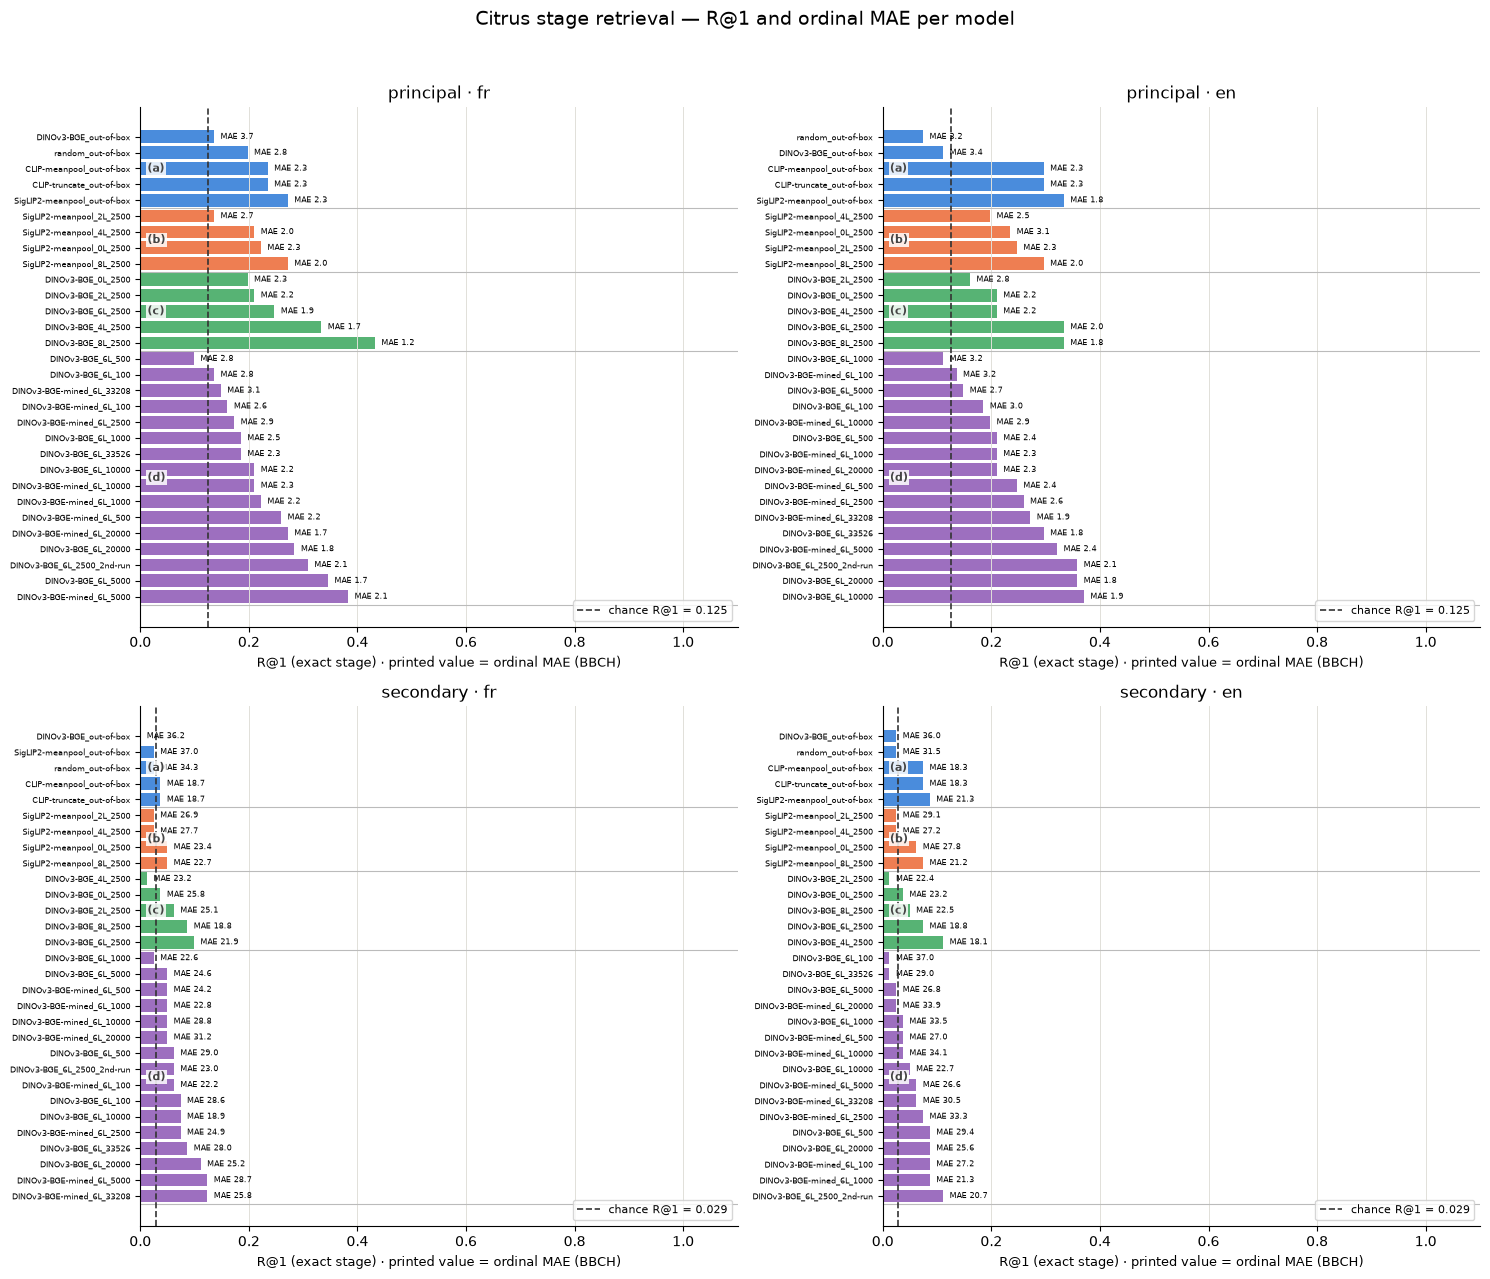

In [13]:
# --- citrus_r1_mae_by_model.pdf ------------------------------------------------
# R@1 per model (bars) with the ordinal MAE printed, per level x language, C0-ordered.
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for ax, level in zip(axes, LEVELS):
    for j, lang in enumerate(LANGUAGES):
        block = cell_summary(level, lang)
        ordered, bounds = c0_axis_order(block["R@1"])
        y = np.arange(len(ordered))
        axj = ax[j] if ax.ndim else ax
        axj.barh(y, [block.loc[m, "R@1"] for m in ordered],
                 color=[C0_COLOR[MODEL_TO_C0[m]] for m in ordered], alpha=0.85)
        for yi, m in zip(y, ordered):
            axj.text(block.loc[m, "R@1"] + 0.012, yi,
                     f"MAE {block.loc[m, 'mae']:.1f}", va="center", fontsize=6)
        draw_c0_blocks(axj, bounds)
        chance = float(block["chance_R@1"].iloc[0])
        axj.axvline(chance, color="#333333", linestyle="--", linewidth=1.2,
                    label=f"chance R@1 = {chance:.3f}")
        axj.set_yticks(y)
        axj.set_yticklabels([model_label(m) for m in ordered], fontsize=6)
        axj.invert_yaxis()
        axj.set_xlim(0, 1.10)
        axj.set_xlabel("R@1 (exact stage) · printed value = ordinal MAE (BBCH)", fontsize=9)
        axj.set_title(f"{level} · {lang}", fontsize=12)
        axj.legend(fontsize=8, loc="lower right")
        style_ax(axj)
fig.suptitle("Citrus stage retrieval — R@1 and ordinal MAE per model",
             fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_fig(fig, "citrus_r1_mae_by_model.pdf")
plt.show()


03:14:14 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_ordinal_mae_families.pdf


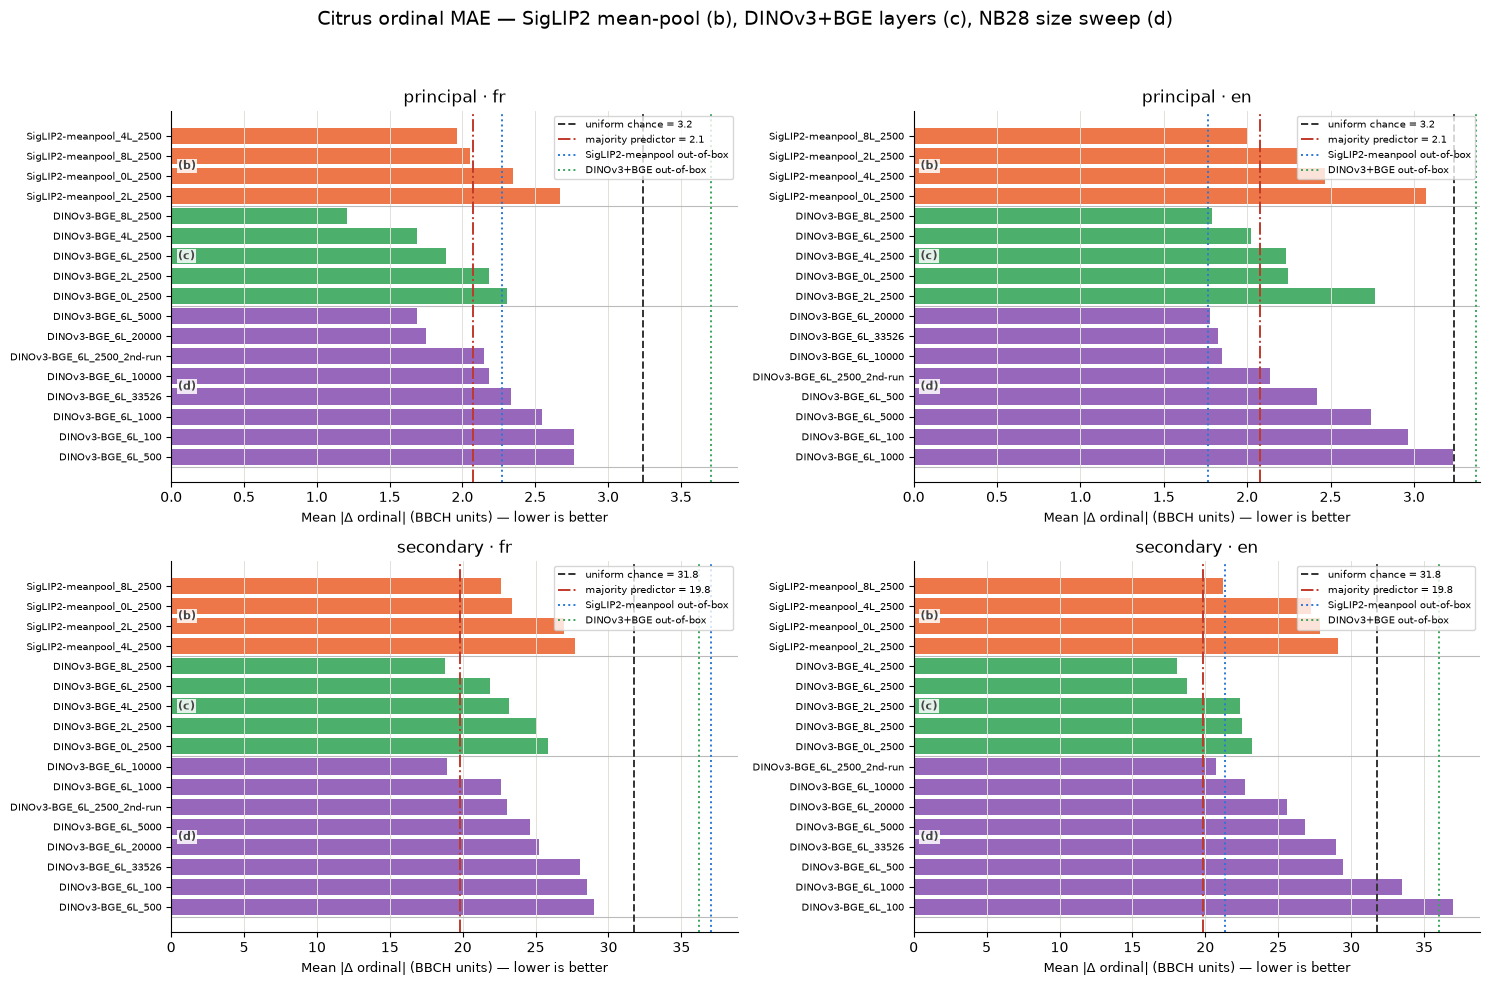

In [14]:
# --- citrus_ordinal_mae_families.pdf -------------------------------------------
# Ordinal MAE for the fine-tuned families only: (b) SigLIP2 mean-pool, (c) DINOv3+BGE
# layers, and the NB28 plain size sweep. Chance and the two out-of-box encoders are
# vertical references (they are not part of the bars).
SELECTED = ([("b", m) for m in C0_MEMBERS["b"]]
            + [("c", m) for m in C0_MEMBERS["c"]]
            + [("d", m) for m in C0_MEMBERS["d"] if m.startswith("smaller_size_")])
COLOR_OF = {m: key for key, m in SELECTED}


def majority_mae(level, lang):
    """MAE of always predicting the modal citrus ground-truth stage of this level."""
    photos = (pred[(pred["level"] == level) & (pred["lang"] == lang)
                   & (pred["model_id"] == MODEL_IDS[0])]
              .drop_duplicates("photo_name"))
    majority_id = photos["gt_id"].value_counts().idxmax()
    majority_ord = float(photos.loc[photos["gt_id"] == majority_id,
                                    "gt_ordinal"].iloc[0])
    return float(np.abs(photos["gt_ordinal"].to_numpy(dtype=float) - majority_ord).mean())

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, level in zip(axes, LEVELS):
    for j, lang in enumerate(LANGUAGES):
        block = cell_summary(level, lang)
        ordered, bounds = [], {}
        for key in ("b", "c", "d"):
            members = [m for k, m in SELECTED if k == key and m in block.index]
            members.sort(key=lambda m: block.loc[m, "mae"])
            bounds[key] = (len(ordered), len(ordered) + len(members))
            ordered += members
        y = np.arange(len(ordered))
        axj = ax[j] if ax.ndim else ax
        axj.barh(y, [block.loc[m, "mae"] for m in ordered],
                 color=[C0_COLOR[COLOR_OF[m]] for m in ordered], alpha=0.9)
        draw_c0_blocks(axj, bounds)
        chance = float(block["chance_mae"].iloc[0])
        axj.axvline(chance, color="#333333", linestyle="--", linewidth=1.4,
                    label=f"uniform chance = {chance:.1f}")
        majority = majority_mae(level, lang)
        axj.axvline(majority, color="#C0392B", linestyle="-.", linewidth=1.4,
                    label=f"majority predictor = {majority:.1f}")
        axj.axvline(block.loc["26_zs_siglip2_meanpool", "mae"], color="#2A78D6",
                    linestyle=":", linewidth=1.4, label="SigLIP2-meanpool out-of-box")
        axj.axvline(block.loc["zz_dinov3_bge_raw", "mae"], color="#3AA65C",
                    linestyle=":", linewidth=1.4, label="DINOv3+BGE out-of-box")
        axj.set_yticks(y)
        axj.set_yticklabels([model_label(m) for m in ordered], fontsize=7)
        axj.invert_yaxis()
        axj.set_xlabel("Mean |Δ ordinal| (BBCH units) — lower is better", fontsize=9)
        axj.set_title(f"{level} · {lang}", fontsize=12)
        axj.legend(fontsize=7, loc="upper right")
        style_ax(axj)
fig.suptitle("Citrus ordinal MAE — SigLIP2 mean-pool (b), DINOv3+BGE layers (c), "
             "NB28 size sweep (d)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "citrus_ordinal_mae_families.pdf")
plt.show()


03:14:15 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_ordinal_mae_families_compact.pdf


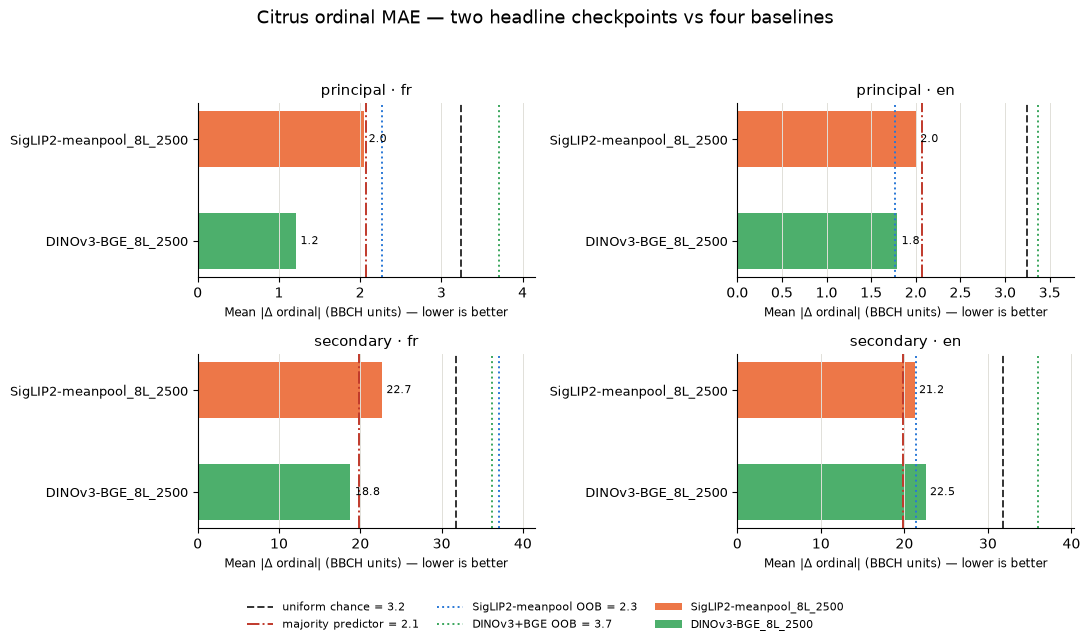

In [15]:
# --- citrus_ordinal_mae_families_compact.pdf -----------------------------------
# Compact version of the family figure: the two headline layer-sweep checkpoints
# (SigLIP2-meanpool_8L_2500 and DINOv3-BGE_8L_2500) against the four reference
# baselines used in the full figure: uniform chance, majority predictor, and the two
# out-of-box encoders.
COMPACT_MODELS = [("b", "27D_last_8"), ("c", "27_last_8")]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
for ax, level in zip(axes, LEVELS):
    for j, lang in enumerate(LANGUAGES):
        block = cell_summary(level, lang)
        axj = ax[j]
        values = [float(block.loc[model_id, "mae"]) for _, model_id in COMPACT_MODELS]
        y = np.arange(len(COMPACT_MODELS))

        for yi, (key, model_id), value in zip(y, COMPACT_MODELS, values):
            axj.barh(yi, value, height=0.55, color=C0_COLOR[key], alpha=0.9,
                     label=model_label(model_id))

        chance = float(block["chance_mae"].iloc[0])
        majority = majority_mae(level, lang)
        oob_siglip = float(block.loc["26_zs_siglip2_meanpool", "mae"])
        oob_dino = float(block.loc["zz_dinov3_bge_raw", "mae"])

        axj.axvline(chance, color="#333333", linestyle="--", linewidth=1.4,
                    label=f"uniform chance = {chance:.1f}")
        axj.axvline(majority, color="#C0392B", linestyle="-.", linewidth=1.4,
                    label=f"majority predictor = {majority:.1f}")
        axj.axvline(oob_siglip, color="#2A78D6", linestyle=":", linewidth=1.4,
                    label=f"SigLIP2-meanpool OOB = {oob_siglip:.1f}")
        axj.axvline(oob_dino, color="#3AA65C", linestyle=":", linewidth=1.4,
                    label=f"DINOv3+BGE OOB = {oob_dino:.1f}")

        xmax = max(values + [chance, majority, oob_siglip, oob_dino])
        axj.set_xlim(0, xmax * 1.12)
        for yi, value in zip(y, values):
            axj.text(value + xmax * 0.015, yi, f"{value:.1f}", va="center", fontsize=8)

        axj.set_yticks(y)
        axj.set_yticklabels([model_label(m) for _, m in COMPACT_MODELS], fontsize=9)
        axj.invert_yaxis()
        axj.set_xlabel("Mean |Δ ordinal| (BBCH units) — lower is better", fontsize=8.5)
        axj.set_title(f"{level} · {lang}", fontsize=11)
        style_ax(axj)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8,
           frameon=False, handlelength=2.4, columnspacing=1.6)
fig.suptitle("Citrus ordinal MAE — two headline checkpoints vs four baselines",
             fontsize=13)
fig.tight_layout(rect=(0, 0.08, 1, 0.94))
save_fig(fig, "citrus_ordinal_mae_families_compact.pdf")
plt.show()


03:14:15 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_ordinal_mae_families_compact_clip.pdf


03:14:16 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus_ordinal_mae_families_compact.pdf


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus_ordinal_mae_families_compact.pdf


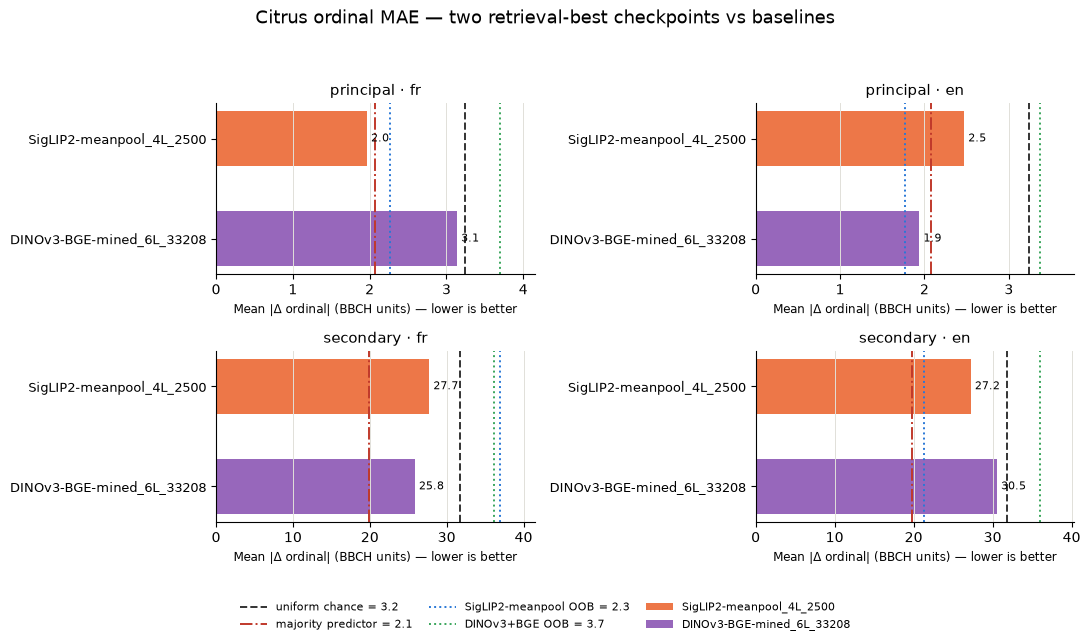

In [16]:
# --- citrus_ordinal_mae_families_compact + CLIP OOB ---------------------------
# Compact figure with a fifth reference baseline (CLIP-meanpool out-of-box) and the
# two retrieval-best checkpoints from NB27-29, not the BBCH-selected ones:
#   SigLIP2 mean-pool -> 27D_last_4       (NB27D best: text->image R@1 0.106)
#   DINOv3+BGE       -> 29_sweep_size_33208 (NB29 best: text->image R@1 0.522)
COMPACT_MODELS_CLIP = [("b", "27D_last_4"), ("d", "29_sweep_size_33208")]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
for ax, level in zip(axes, LEVELS):
    for j, lang in enumerate(LANGUAGES):
        block = cell_summary(level, lang)
        axj = ax[j]
        values = [float(block.loc[model_id, "mae"])
                  for _, model_id in COMPACT_MODELS_CLIP]
        y = np.arange(len(COMPACT_MODELS_CLIP))

        for yi, (key, model_id), value in zip(y, COMPACT_MODELS_CLIP, values):
            axj.barh(yi, value, height=0.55, color=C0_COLOR[key], alpha=0.9,
                     label=model_label(model_id))

        chance = float(block["chance_mae"].iloc[0])
        majority = majority_mae(level, lang)
        oob_siglip = float(block.loc["26_zs_siglip2_meanpool", "mae"])
        oob_dino = float(block.loc["zz_dinov3_bge_raw", "mae"])
        oob_clip = float(block.loc["26_zs_clip_meanpool", "mae"])

        axj.axvline(chance, color="#333333", linestyle="--", linewidth=1.4,
                    label=f"uniform chance = {chance:.1f}")
        axj.axvline(majority, color="#C0392B", linestyle="-.", linewidth=1.4,
                    label=f"majority predictor = {majority:.1f}")
        axj.axvline(oob_siglip, color="#2A78D6", linestyle=":", linewidth=1.4,
                    label=f"SigLIP2-meanpool OOB = {oob_siglip:.1f}")
        axj.axvline(oob_dino, color="#3AA65C", linestyle=":", linewidth=1.4,
                    label=f"DINOv3+BGE OOB = {oob_dino:.1f}")
        #axj.axvline(oob_clip, color="#8C56B4", linestyle=":", linewidth=1.4,
        #            label=f"CLIP-meanpool OOB = {oob_clip:.1f}")

        xmax = max(values + [chance, majority, oob_siglip, oob_dino, oob_clip])
        axj.set_xlim(0, xmax * 1.12)
        for yi, value in zip(y, values):
            axj.text(value + xmax * 0.015, yi, f"{value:.1f}", va="center", fontsize=8)

        axj.set_yticks(y)
        axj.set_yticklabels([model_label(m) for _, m in COMPACT_MODELS_CLIP], fontsize=9)
        axj.invert_yaxis()
        axj.set_xlabel("Mean |Δ ordinal| (BBCH units) — lower is better", fontsize=8.5)
        axj.set_title(f"{level} · {lang}", fontsize=11)
        style_ax(axj)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8,
           frameon=False, handlelength=2.4, columnspacing=1.5)
fig.suptitle("Citrus ordinal MAE — two retrieval-best checkpoints vs baselines",
             fontsize=13)
fig.tight_layout(rect=(0, 0.09, 1, 0.94))
save_fig(fig, "citrus_ordinal_mae_families_compact_clip.pdf")

# Exact path requested for this supplementary-baseline variant (figures/ root).
root_path = FIG_DIR / "citrus_ordinal_mae_families_compact.pdf"
fig.savefig(root_path, bbox_inches="tight")
logger.info("Wrote %s", root_path)
print(f"Wrote {root_path}")
plt.show()


03:14:16 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_oob_vs_best_finetuned.pdf


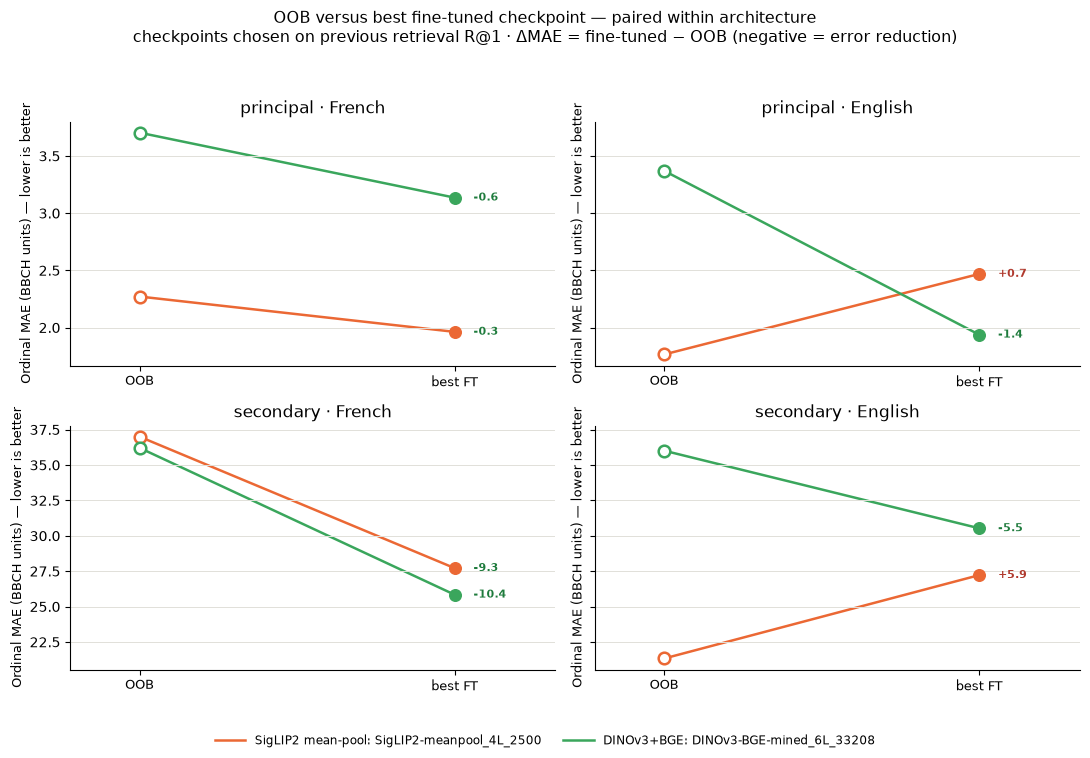

Checkpoint selection (NB27-29 retrieval R@1, text->image):
  SigLIP2 mean-pool: SigLIP2-meanpool_4L_2500
  DINOv3+BGE: DINOv3-BGE-mined_6L_33208
ΔMAE labels: fine-tuned − OOB; negative (green) = BBCH error reduction.


In [17]:
# --- citrus_oob_vs_best_finetuned.pdf ------------------------------------------
# Paired comparison, one pair per architecture: the out-of-box encoder versus the
# single best fine-tuned checkpoint of that architecture. Checkpoints are chosen from
# the NB27-29 retrieval results, NOT from the BBCH evaluation:
#   criterion = highest text->image R@1 on the N=500 retrieval validation set (the
#   direction that matches image->stage retrieval); averaging both directions gives the
#   same winners.
#   * NB27D SigLIP2 mean-pool layer sweep: 27D_last_4
#       R@1 text->image 0.106, two-direction mean 0.101 (next: 27D_last_16 0.104/0.100;
#       27D_last_8 0.102/0.097)
#   * NB29 DINOv3+BGE mining sweep: 29_sweep_size_33208
#       R@1 text->image 0.522, two-direction mean 0.518
#       (beats NB27's best layer 27_last_4: 0.220/0.219, and NB28's full-size plain
#       run smaller_size_33526: 0.512/0.515)
OOB_OF = {
    "SigLIP2 mean-pool": "26_zs_siglip2_meanpool",
    "DINOv3+BGE": "zz_dinov3_bge_raw",
}
FAMILY_MEMBERS = {
    "SigLIP2 mean-pool": [m for m in C0_MEMBERS["b"] if m in MODEL_IDS],
    "DINOv3+BGE": [m for m in C0_MEMBERS["c"] + C0_MEMBERS["d"] if m in MODEL_IDS],
}
FAMILY_COLOR = {"SigLIP2 mean-pool": C0_COLOR["b"], "DINOv3+BGE": C0_COLOR["c"]}
BEST_FT = {
    "SigLIP2 mean-pool": "27D_last_4",          # NB27D retrieval winner
    "DINOv3+BGE": "29_sweep_size_33208",        # NB29 retrieval winner
}
assert all(BEST_FT[f] in FAMILY_MEMBERS[f] for f in BEST_FT)

fig, axes = plt.subplots(2, 2, figsize=(11, 7.6), sharey="row")
for ax, level in zip(axes, LEVELS):
    for j, lang in enumerate(LANGUAGES):
        block = cell_summary(level, lang)
        axj = ax[j]
        for family in OOB_OF:
            oob_id = OOB_OF[family]
            ft_id = BEST_FT[family]
            oob_mae = float(block.loc[oob_id, "mae"])
            ft_mae = float(block.loc[ft_id, "mae"])
            color = FAMILY_COLOR[family]

            axj.plot([0, 1], [oob_mae, ft_mae], color=color, linewidth=1.8, zorder=1,
                     label=f"{family}: {model_label(ft_id)}")
            axj.scatter([0], [oob_mae], s=70, facecolors="white", edgecolors=color,
                        linewidths=1.8, zorder=2)
            axj.scatter([1], [ft_mae], s=70, color=color, edgecolors=color, zorder=2)

            # ΔMAE = fine-tuned − OOB; negative = error reduction, positive = regression.
            delta = ft_mae - oob_mae
            axj.text(1.06, ft_mae, f"{delta:+.1f}", va="center", ha="left", fontsize=8,
                     color=("#1E7B3C" if delta < 0 else "#B03A2E"),
                     fontweight="bold")

        axj.set_xlim(-0.22, 1.32)
        axj.set_xticks([0, 1])
        axj.set_xticklabels(["OOB", "best FT"], fontsize=9)
        axj.set_ylabel("Ordinal MAE (BBCH units) — lower is better", fontsize=9)
        axj.set_title(f"{level} · {'French' if lang == 'fr' else 'English'}",
                      fontsize=12)
        axj.grid(axis="y", color=GRID_COLOR, linewidth=0.7)
        axj.spines["top"].set_visible(False)
        axj.spines["right"].set_visible(False)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=8.5,
           frameon=False, handlelength=2.6, columnspacing=1.8)
fig.suptitle("OOB versus best fine-tuned checkpoint — paired within architecture\n"
             "checkpoints chosen on previous retrieval R@1 · "
             "ΔMAE = fine-tuned − OOB (negative = error reduction)",
             fontsize=11.5)
fig.tight_layout(rect=(0, 0.06, 1, 0.95))
save_fig(fig, "citrus_oob_vs_best_finetuned.pdf")
plt.show()
print("Checkpoint selection (NB27-29 retrieval R@1, text->image):")
for family, model_id in BEST_FT.items():
    print(f"  {family}: {model_label(model_id)}")
print("ΔMAE labels: fine-tuned − OOB; negative (green) = BBCH error reduction.")


03:14:17 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_ordinal_distance_cdf.pdf


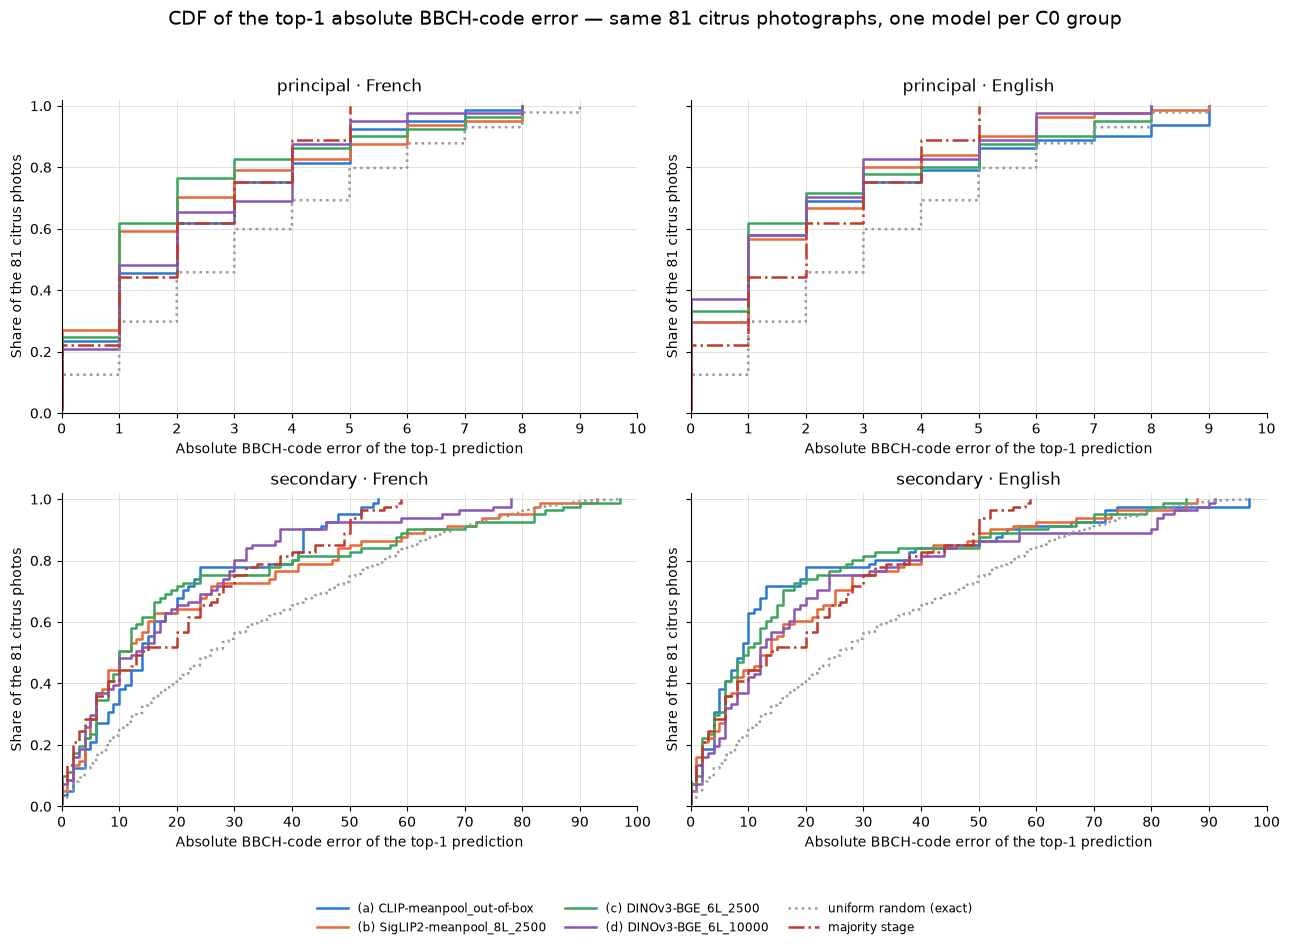

In [18]:
# --- citrus_ordinal_distance_cdf.pdf -------------------------------------------
# CDF of the top-1 absolute BBCH-code error for the SAME 81 citrus photographs in every
# panel. Rows = level (principal / secondary), columns = language (fr / en). One model
# per C0 group is used in all four panels, chosen by its mean within-level MAE rank
# across the two levels, so colours and configurations are matched across languages.
# Baselines: uniform random over the candidate pool and the majority-stage predictor.
def citrus_photo_rows(level, lang):
    """The 81 citrus photos with their ground-truth ordinal (one row per photo)."""
    photos = pred[(pred["level"] == level) & (pred["lang"] == lang)
                  & (pred["model_id"] == MODEL_IDS[0])]
    return photos.drop_duplicates("photo_name")


def uniform_distances(level, lang):
    """Exact uniform-random null: every candidate stage for every citrus photo."""
    pool = np.array([float(stage_id) for stage_id in pool_ids(level)])
    gt = citrus_photo_rows(level, lang)["gt_ordinal"].to_numpy(dtype=float)
    return np.abs(pool[:, None] - gt[None, :]).ravel()


def majority_distances(level, lang):
    """Per-photo errors of the majority-stage predictor for this level."""
    photos = citrus_photo_rows(level, lang)
    majority_id = photos["gt_id"].value_counts().idxmax()
    majority_ord = float(majority_id)          # citrus ids are native BBCH
    return np.abs(photos["gt_ordinal"].to_numpy(dtype=float) - majority_ord)


def ecdf(values):
    x = np.sort(np.asarray(values, dtype=float))
    return x, np.arange(1, len(x) + 1) / len(x)


for level in LEVELS:
    for lang in LANGUAGES:
        assert len(citrus_photo_rows(level, lang)) == 81,             f"{level}/{lang}: expected the 81 citrus photos"

# Rank models inside each level first, then average the ranks, so the larger secondary
# distances do not dominate the choice. One model per group is used everywhere.
level_rank = []
for level in LEVELS:
    mae = pred[pred["level"] == level].groupby("model_id")["ordinal_distance"].mean()
    level_rank.append(mae.rank(method="average"))
combined_rank = sum(level_rank) / len(level_rank)
chosen = {}
for key in C0_ORDER:
    members = [m for m in C0_MEMBERS[key] if m in combined_rank.index]
    if members:
        chosen[key] = min(members, key=lambda m: combined_rank[m])

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), sharex="row", sharey=True)
for i, level in enumerate(LEVELS):
    for j, lang in enumerate(LANGUAGES):
        ax = axes[i, j]
        for key in C0_ORDER:
            if key not in chosen:
                continue
            model_id = chosen[key]
            d = pred[(pred["model_id"] == model_id)
                     & (pred["level"] == level)
                     & (pred["lang"] == lang)]["ordinal_distance"].to_numpy()
            x, y = ecdf(d)
            ax.plot(x, y, drawstyle="steps-post", color=C0_COLOR[key], linewidth=1.8,
                    label=f"({key}) {model_label(model_id)}")

        xu, yu = ecdf(uniform_distances(level, lang))
        ax.plot(xu, yu, drawstyle="steps-post", color="#999999", linestyle=":",
                linewidth=1.8, label="uniform random (exact)")
        xm, ym = ecdf(majority_distances(level, lang))
        ax.plot(xm, ym, drawstyle="steps-post", color="#C0392B", linestyle="-.",
                linewidth=1.8, label="majority stage")

        if level == "principal":
            ax.set_xlim(0, 10)
            ax.set_xticks(range(0, 11))
        else:
            ax.set_xlim(0, 100)
            ax.set_xticks(range(0, 101, 10))
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("Absolute BBCH-code error of the top-1 prediction", fontsize=10)
        ax.set_ylabel("Share of the 81 citrus photos", fontsize=10)
        ax.set_title(f"{level} · {'French' if lang == 'fr' else 'English'}", fontsize=12)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(color=GRID_COLOR, linewidth=0.7)

# one compact legend shared by all four panels
handles, labels, seen = [], [], set()
for ax in axes.ravel():
    for handle, label in zip(*ax.get_legend_handles_labels()):
        if label not in seen:
            seen.add(label)
            handles.append(handle)
            labels.append(label)
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8.5,
           frameon=False, handlelength=2.6, columnspacing=1.6)
fig.suptitle("CDF of the top-1 absolute BBCH-code error — same 81 citrus photographs, "
             "one model per C0 group", fontsize=14)
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
save_fig(fig, "citrus_ordinal_distance_cdf.pdf")
plt.show()


03:14:17 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_per_stage_recall_principal.pdf


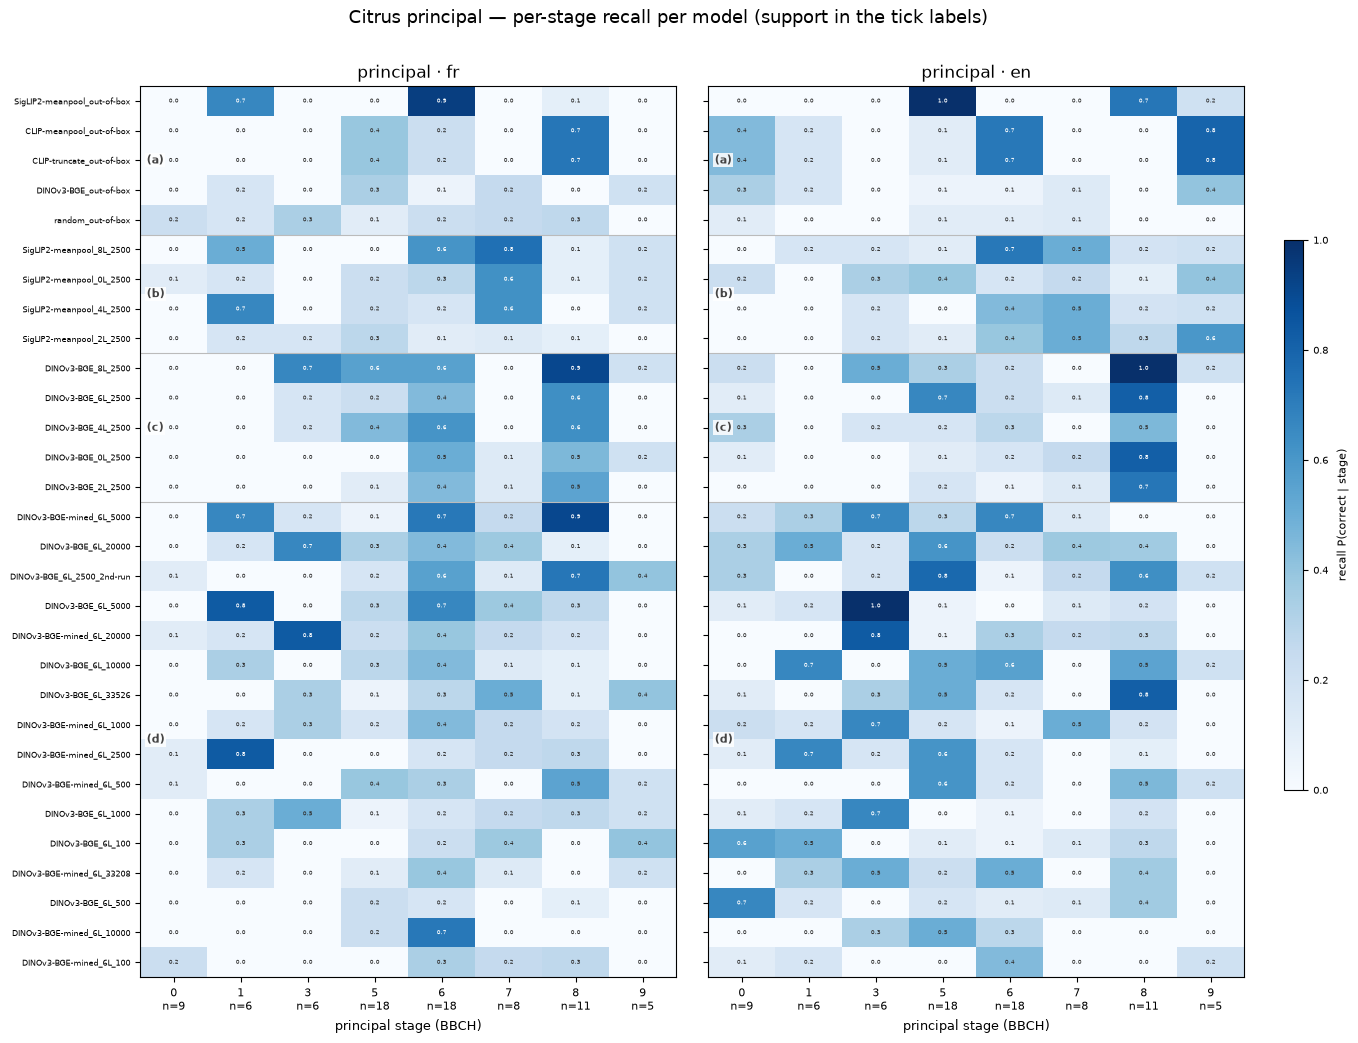

In [19]:
# --- citrus_per_stage_recall_principal.pdf --------------------------------------
# Heatmap: model (C0 order) x principal stage, cell = recall. Support in the tick labels.
pool_p = pool_ids("principal")
support_p = (df_stage[(df_stage["level"] == "principal") & (df_stage["lang"] == "fr")]
             .drop_duplicates("stage_id").set_index("stage_id")["support"].reindex(pool_p))

fig, axes = plt.subplots(1, 2, figsize=(16, 11), sharey=True)
# One common model order across both languages: with a shared y-axis, ordering each
# panel by its own language would attach the last panel's labels to the other's rows.
rec_by_lang = {
    lang: (df_stage[(df_stage["level"] == "principal") & (df_stage["lang"] == lang)]
           .pivot(index="model_id", columns="stage_id", values="recall")
           .reindex(index=MODEL_IDS, columns=pool_p))
    for lang in LANGUAGES
}
mean_rec = pd.concat([rec_by_lang[lang].mean(axis=1) for lang in LANGUAGES],
                     axis=1).mean(axis=1)
ordered, bounds = c0_axis_order(mean_rec, ascending=False)
for ax, lang in zip(axes, LANGUAGES):
    rec = rec_by_lang[lang].loc[ordered]
    im = ax.imshow(rec.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    draw_c0_blocks(ax, bounds)
    ax.set_xticks(range(len(pool_p)))
    ax.set_xticklabels([f"{s}\nn={int(support_p[s])}" for s in pool_p], fontsize=8)
    ax.set_yticks(range(len(ordered)))
    ax.set_yticklabels([model_label(m) for m in ordered], fontsize=6)
    ax.set_xlabel("principal stage (BBCH)", fontsize=9)
    ax.set_title(f"principal · {lang}", fontsize=12)
    for i in range(rec.shape[0]):
        for j in range(rec.shape[1]):
            v = rec.iloc[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=4.5,
                        color="white" if v > 0.55 else "#333333")
fig.subplots_adjust(left=0.17, right=0.86, top=0.91, bottom=0.10, wspace=0.06)
cax = fig.add_axes([0.885, 0.27, 0.012, 0.50])
cb = fig.colorbar(im, cax=cax)
cb.set_label("recall P(correct | stage)", fontsize=8, labelpad=6)
cb.ax.tick_params(labelsize=7)
fig.suptitle("Citrus principal — per-stage recall per model (support in the tick labels)",
             fontsize=13)
save_fig(fig, "citrus_per_stage_recall_principal.pdf")
plt.show()


03:14:18 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_per_stage_recall_secondary.pdf


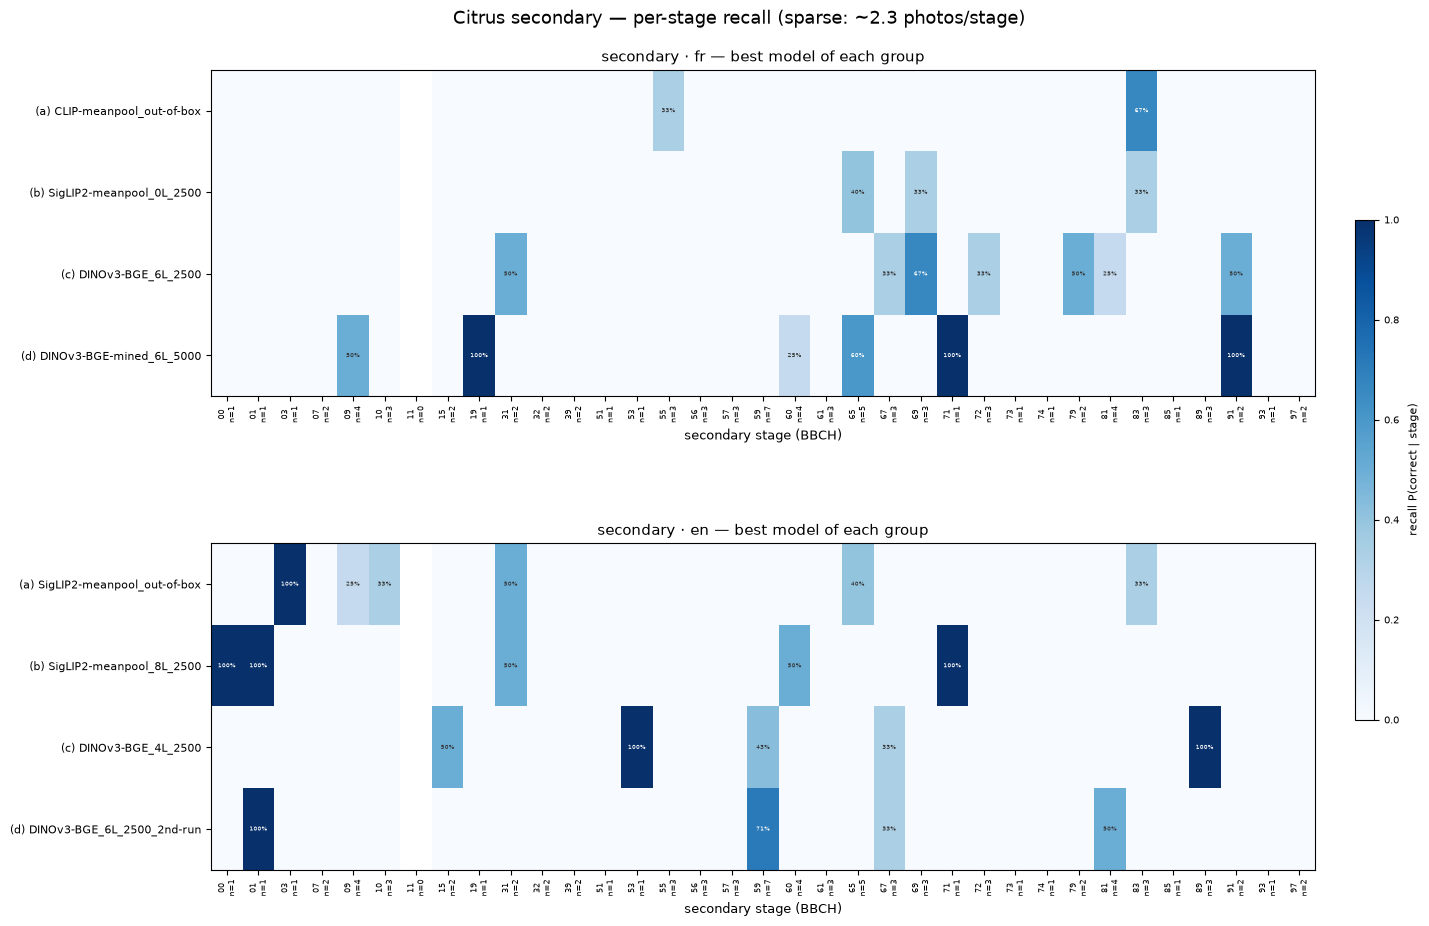

In [20]:
# --- citrus_per_stage_recall_secondary.pdf --------------------------------------
# Best model of each C0 group (by R@1) x 35 secondary stages, recall, per language.
pool_s = pool_ids("secondary")
support_s = (df_stage[(df_stage["level"] == "secondary") & (df_stage["lang"] == "fr")]
             .drop_duplicates("stage_id").set_index("stage_id")["support"].reindex(pool_s))

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
for ax, lang in zip(axes, LANGUAGES):
    best = best_per_c0("secondary", lang, "R@1", ascending=False)
    rows = [(k, best[k]) for k in C0_ORDER if k in best]
    mat = []
    for key, model_id in rows:
        s = (df_stage[(df_stage["model_id"] == model_id) & (df_stage["level"] == "secondary")
                      & (df_stage["lang"] == lang)]
             .set_index("stage_id")["recall"].reindex(pool_s))
        mat.append(s.to_numpy(dtype=float))
    mat = np.vstack(mat)
    im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([f"({k}) {model_label(m)}" for k, m in rows], fontsize=8)
    ax.set_xticks(range(len(pool_s)))
    ax.set_xticklabels([f"{s}\nn={int(support_s[s])}" for s in pool_s],
                       rotation=90, fontsize=6)
    ax.set_xlabel("secondary stage (BBCH)", fontsize=9)
    ax.set_title(f"secondary · {lang} — best model of each group", fontsize=11)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if np.isfinite(mat[i, j]) and mat[i, j] > 0:
                ax.text(j, i, f"{mat[i, j]:.0%}", ha="center", va="center", fontsize=4.5,
                        color="white" if mat[i, j] > 0.55 else "#333333")
fig.subplots_adjust(left=0.17, right=0.86, top=0.92, bottom=0.12, hspace=0.45)
cax = fig.add_axes([0.885, 0.27, 0.012, 0.50])
cb = fig.colorbar(im, cax=cax)
cb.set_label("recall P(correct | stage)", fontsize=8, labelpad=6)
cb.ax.tick_params(labelsize=7)
fig.suptitle("Citrus secondary — per-stage recall (sparse: ~2.3 photos/stage)",
             fontsize=13)
save_fig(fig, "citrus_per_stage_recall_secondary.pdf")
plt.show()


03:14:19 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_confusion_principal.pdf


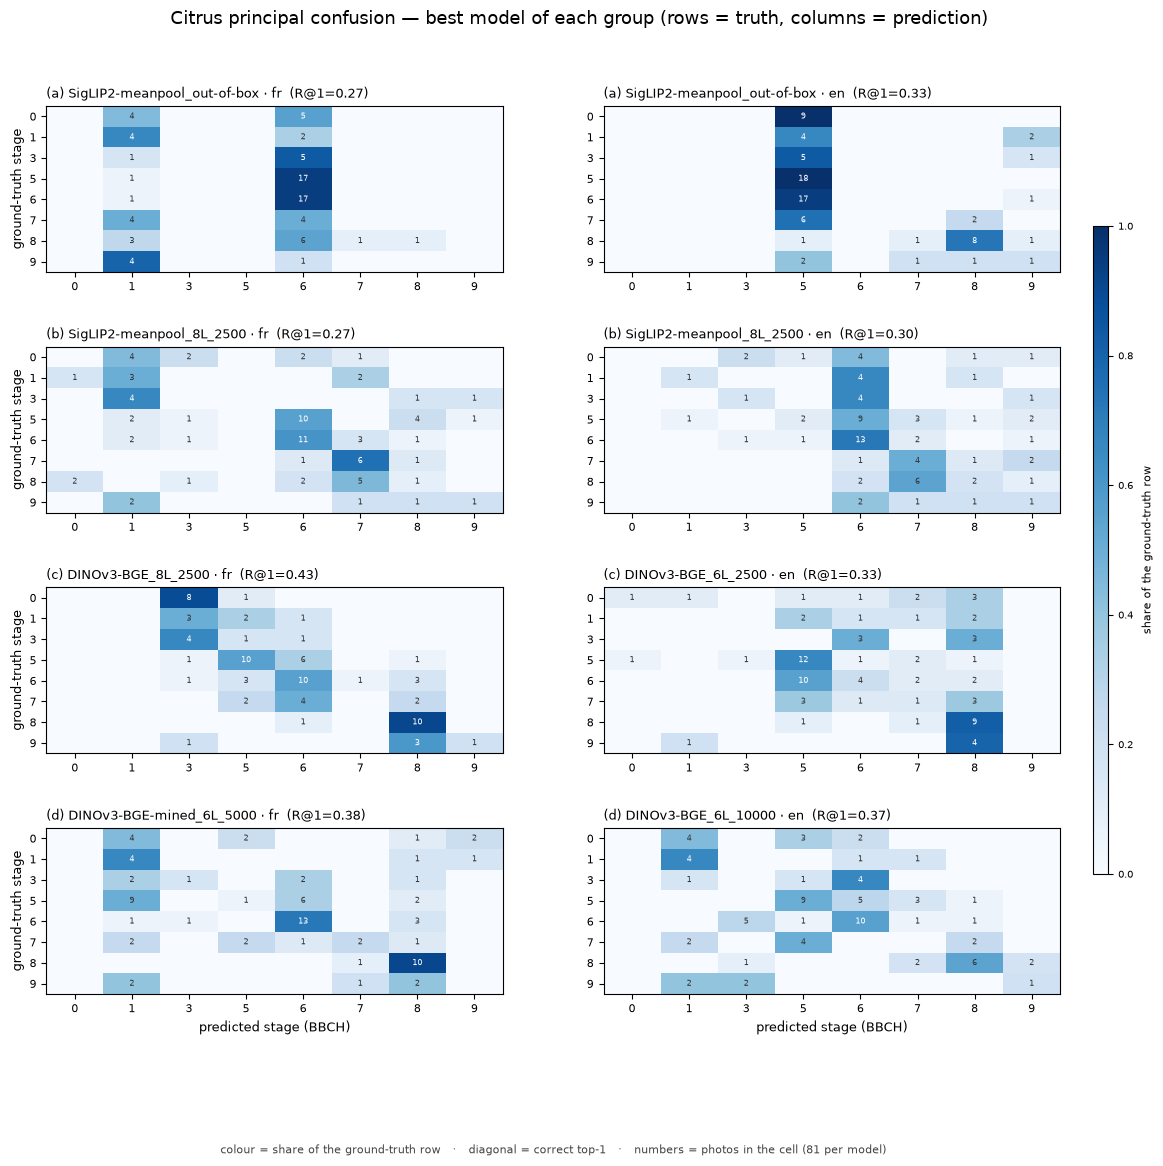

In [21]:
# --- citrus_confusion_principal.pdf ---------------------------------------------
# Best model of each C0 group (by R@1) per language; 8 x 8 with counts annotated.
pool_p = pool_ids("principal")
fig, axes = plt.subplots(len(C0_ORDER), len(LANGUAGES), figsize=(13, 12), squeeze=False)
im = None
for j, lang in enumerate(LANGUAGES):
    best = best_per_c0("principal", lang, "R@1", ascending=False)
    for i, key in enumerate(C0_ORDER):
        ax = axes[i, j]
        if key not in best:
            ax.axis("off")
            continue
        model_id = best[key]
        mat = confusion_matrix(model_id, "principal", lang)
        rn = mat.div(mat.sum(axis=1).replace(0, np.nan), axis=0)
        im = ax.imshow(rn.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(pool_p)))
        ax.set_xticklabels(pool_p, fontsize=8)
        ax.set_yticks(range(len(pool_p)))
        ax.set_yticklabels(pool_p, fontsize=8)
        if i == len(C0_ORDER) - 1:                  # label the outer panels only
            ax.set_xlabel("predicted stage (BBCH)", fontsize=9)
        if j == 0:
            ax.set_ylabel("ground-truth stage", fontsize=9)
        ax.set_title(f"({key}) {model_label(model_id)} · {lang}  "
                     f"(R@1={cell_summary('principal', lang).loc[model_id, 'R@1']:.2f})",
                     fontsize=9, loc="left")
        for a in range(mat.shape[0]):
            for b in range(mat.shape[1]):
                c = int(mat.iloc[a, b])
                if c:
                    ax.text(b, a, str(c), ha="center", va="center", fontsize=6,
                            color="white" if rn.iloc[a, b] > 0.55 else "#333333")
fig.subplots_adjust(left=0.09, right=0.87, top=0.90, bottom=0.16,
                    hspace=0.45, wspace=0.22)
cax = fig.add_axes([0.895, 0.26, 0.012, 0.54])      # dedicated colour-bar axes
cb = fig.colorbar(im, cax=cax)
cb.set_label("share of the ground-truth row", fontsize=8, labelpad=6)
cb.ax.tick_params(labelsize=7)
# caption: fixed text under the panels, so it never collides with the axis labels
fig.text(0.48, 0.025,
         "colour = share of the ground-truth row   ·   diagonal = correct top-1   ·   "
         "numbers = photos in the cell (81 per model)",
         ha="center", va="bottom", fontsize=8, color="#444444")
fig.suptitle("Citrus principal confusion — best model of each group "
             "(rows = truth, columns = prediction)", fontsize=13)
save_fig(fig, "citrus_confusion_principal.pdf")
plt.show()


03:14:20 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_confusion_secondary.pdf


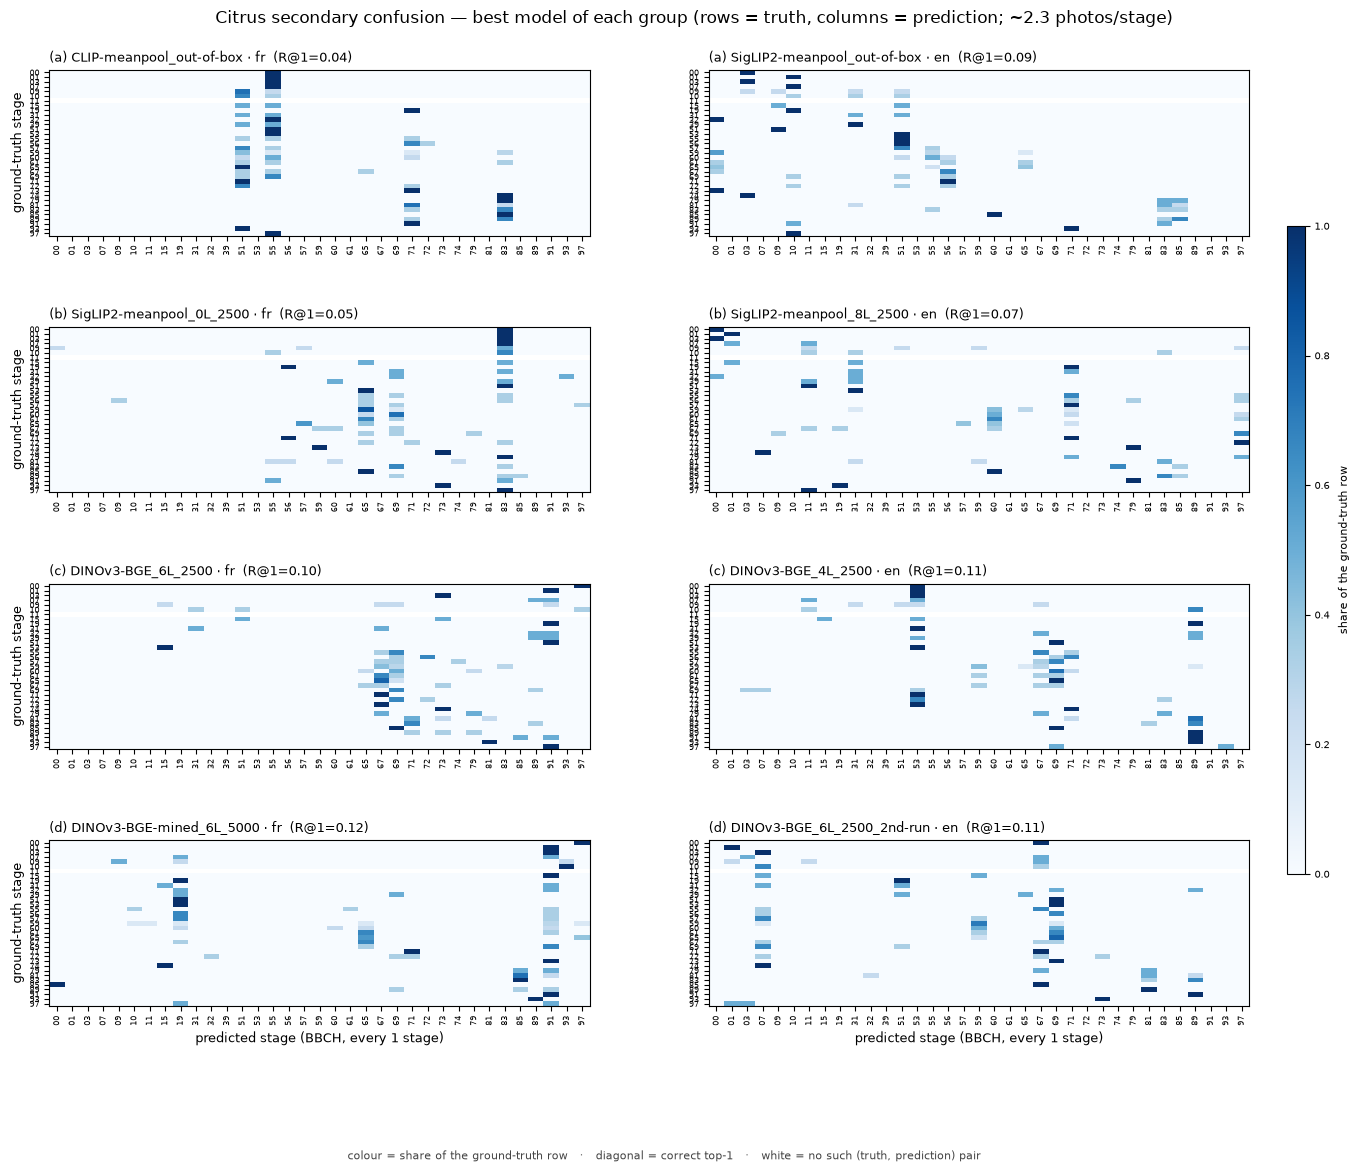

In [22]:
# --- citrus_confusion_secondary.pdf ---------------------------------------------
# Best model of each C0 group (by R@1) per language; 35 x 35, row-normalized.
pool_s = pool_ids("secondary")
step = max(1, int(np.ceil(len(pool_s) / 35)))
tick_pos = list(range(0, len(pool_s), step))
fig, axes = plt.subplots(len(C0_ORDER), len(LANGUAGES),
                         figsize=(15, 3.0 * len(C0_ORDER)), squeeze=False)
im = None
for j, lang in enumerate(LANGUAGES):
    best = best_per_c0("secondary", lang, "R@1", ascending=False)
    for i, key in enumerate(C0_ORDER):
        ax = axes[i, j]
        if key not in best:
            ax.axis("off")
            continue
        model_id = best[key]
        mat = confusion_matrix(model_id, "secondary", lang)
        rn = mat.div(mat.sum(axis=1).replace(0, np.nan), axis=0)
        im = ax.imshow(rn.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(tick_pos)
        ax.set_xticklabels([pool_s[t] for t in tick_pos], rotation=90, fontsize=6)
        ax.set_yticks(tick_pos)
        ax.set_yticklabels([pool_s[t] for t in tick_pos], fontsize=6)
        if i == len(C0_ORDER) - 1:
            ax.set_xlabel(f"predicted stage (BBCH, every {step}"
                          f"{' stage' if step == 1 else ' stages'})", fontsize=9)
        if j == 0:
            ax.set_ylabel("ground-truth stage", fontsize=9)
        ax.set_title(f"({key}) {model_label(model_id)} · {lang}  "
                     f"(R@1={cell_summary('secondary', lang).loc[model_id, 'R@1']:.2f})",
                     fontsize=9, loc="left")
fig.subplots_adjust(left=0.07, right=0.87, top=0.93, bottom=0.15,
                    hspace=0.55, wspace=0.22)
cax = fig.add_axes([0.895, 0.26, 0.012, 0.54])      # dedicated colour-bar axes
cb = fig.colorbar(im, cax=cax)
cb.set_label("share of the ground-truth row", fontsize=8, labelpad=6)
cb.ax.tick_params(labelsize=7)
fig.text(0.48, 0.02,
         "colour = share of the ground-truth row   ·   diagonal = correct top-1   ·   "
         "white = no such (truth, prediction) pair",
         ha="center", va="bottom", fontsize=8, color="#444444")
fig.suptitle("Citrus secondary confusion — best model of each group "
             "(rows = truth, columns = prediction; ~2.3 photos/stage)",
             fontsize=12)
save_fig(fig, "citrus_confusion_secondary.pdf")
plt.show()


03:14:21 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_hierarchy.pdf


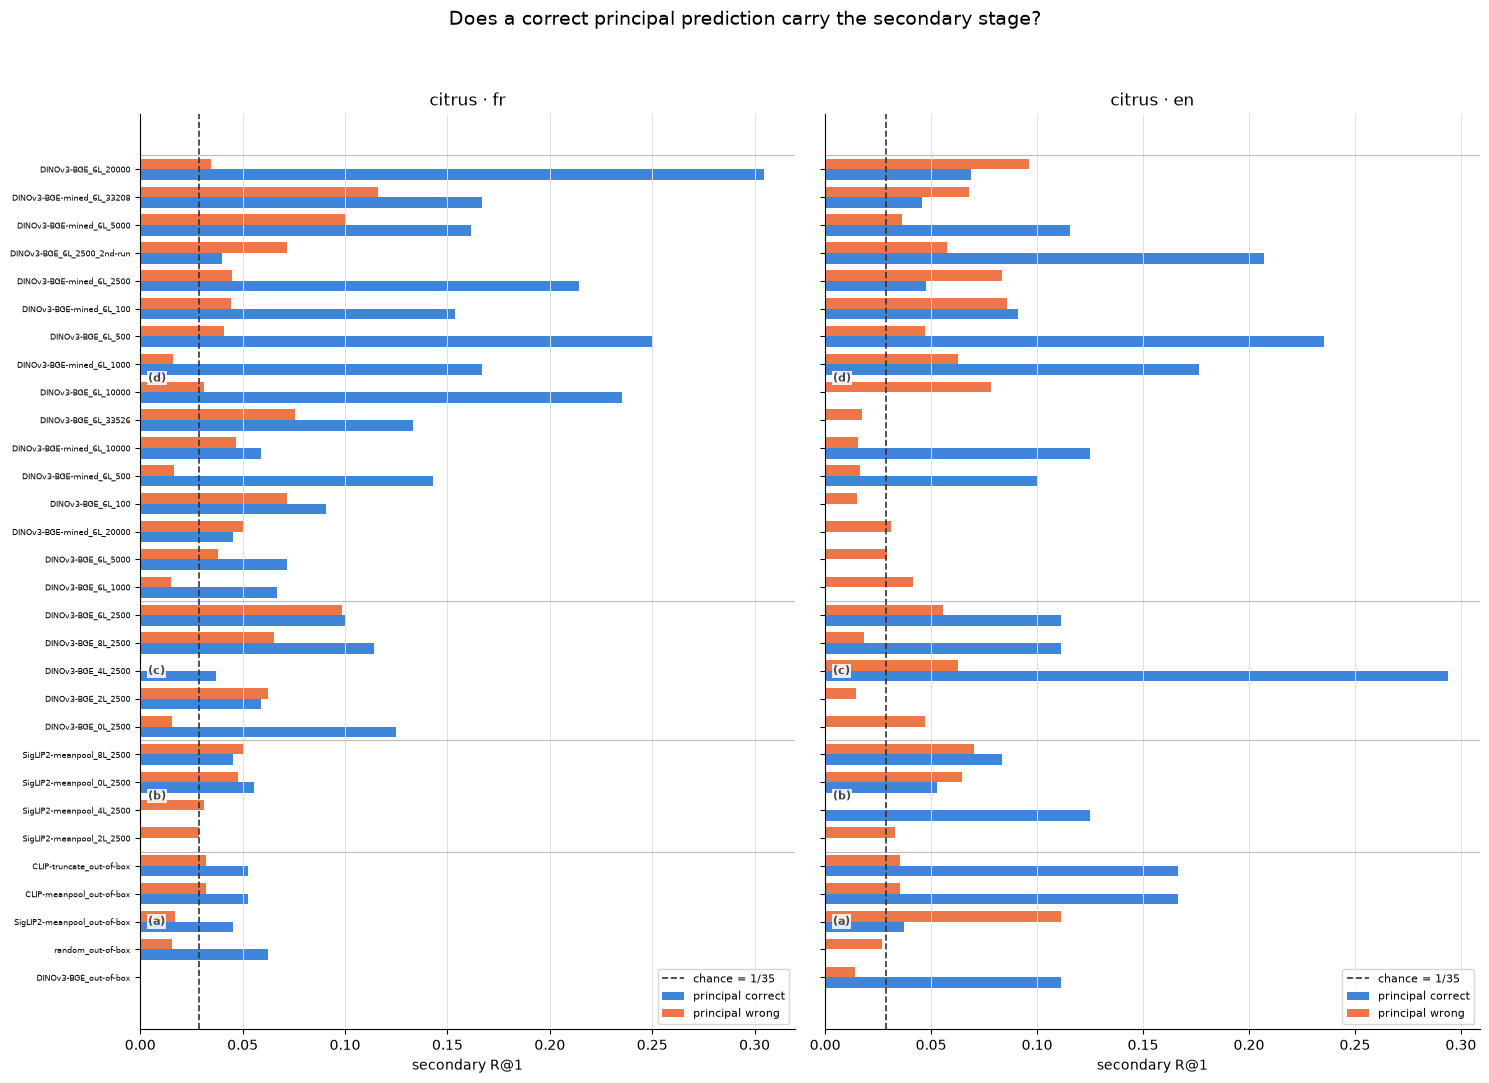

In [23]:
# --- citrus_hierarchy.pdf -------------------------------------------------------
# Secondary R@1 conditioned on the principal top-1 being right / wrong, per model.
fig, axes = plt.subplots(1, 2, figsize=(15, 11), sharey=True)
# Common model order across languages (shared y-axis, so the row labels must match).
hier_by_lang = {lang: df_hier[df_hier["lang"] == lang].set_index("model_id")
                for lang in LANGUAGES}
mean_sec_r1 = pd.concat([hier_by_lang[lang]["sec_R@1"] for lang in LANGUAGES],
                        axis=1).mean(axis=1)
ordered, bounds = c0_axis_order(mean_sec_r1)
for ax, lang in zip(axes, LANGUAGES):
    block = hier_by_lang[lang].loc[ordered]
    y = np.arange(len(ordered))
    h = 0.38
    ax.barh(y - h / 2, [block.loc[m, "sec_R@1_given_pri_correct"] for m in ordered],
            height=h, color="#2A78D6", alpha=0.9, label="principal correct")
    ax.barh(y + h / 2, [block.loc[m, "sec_R@1_given_pri_wrong"] for m in ordered],
            height=h, color="#EB6834", alpha=0.9, label="principal wrong")
    draw_c0_blocks(ax, bounds)
    ax.axvline(1.0 / POOL_SIZE["secondary"], color="#333333", linestyle="--", linewidth=1.2,
               label=f"chance = 1/{POOL_SIZE['secondary']}")
    ax.set_yticks(y)
    ax.set_yticklabels([model_label(m) for m in ordered], fontsize=6)
    ax.invert_yaxis()
    ax.set_xlabel("secondary R@1", fontsize=10)
    ax.set_title(f"citrus · {lang}", fontsize=12)
    ax.legend(fontsize=8, loc="lower right")
    style_ax(ax)
fig.suptitle("Does a correct principal prediction carry the secondary stage?", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "citrus_hierarchy.pdf")
plt.show()


03:14:22 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_error_by_principal.pdf


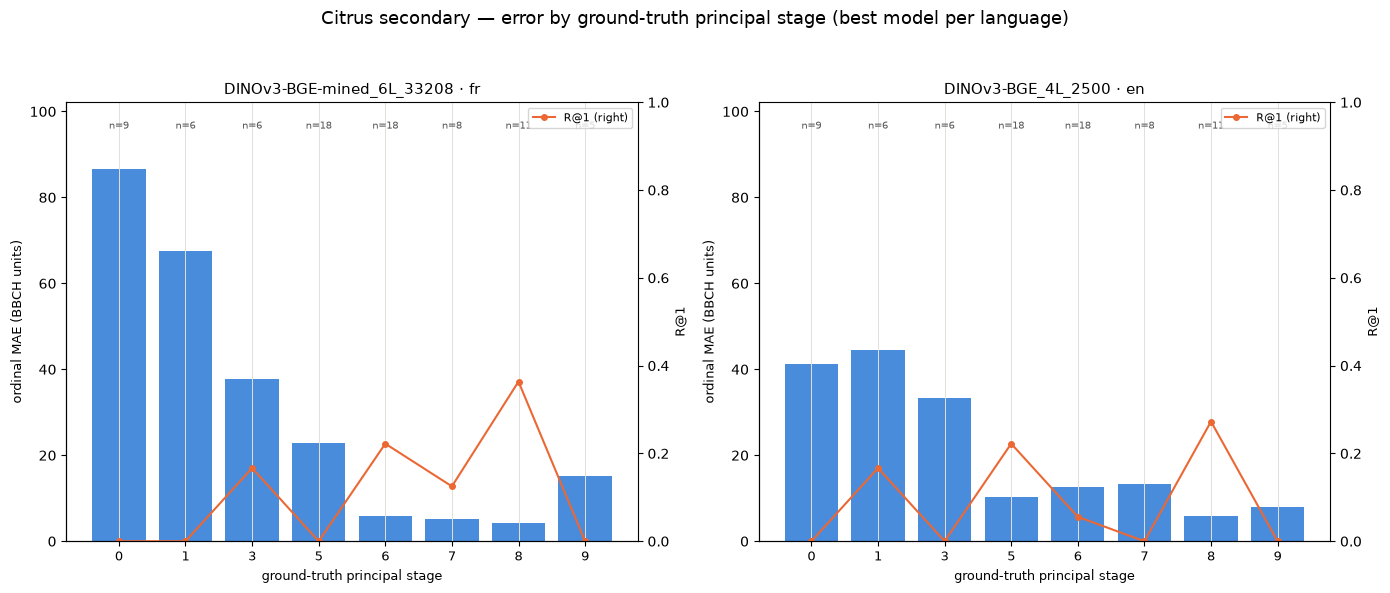

In [24]:
# --- citrus_error_by_principal.pdf ---------------------------------------------
# Reference model per language (best secondary R@1): MAE and R@1 by ground-truth principal.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Resolve both reference models first so the MAE axis is shared across languages.
panels = {}
for lang in LANGUAGES:
    best_id = df_summary[(df_summary["level"] == "secondary") & (df_summary["lang"] == lang)] \
        .sort_values("R@1", ascending=False).iloc[0]["model_id"]
    panels[lang] = (best_id, df_season[(df_season["model_id"] == best_id)
                                       & (df_season["lang"] == lang)]
                    .sort_values("gt_principal"))
mae_top = max(block["mae"].max() for _, block in panels.values()) * 1.18
for ax, lang in zip(axes, LANGUAGES):
    best_id, block = panels[lang]
    x = np.arange(len(block))
    ax.bar(x, block["mae"], color="#2A78D6", alpha=0.85)
    ax.set_ylim(0, max(mae_top, 1.0))
    for xi, n in zip(x, block["N"]):
        ax.text(xi, ax.get_ylim()[1] * 0.94, f"n={int(n)}", ha="center",
                fontsize=7, color="#555555")
    ax.set_xticks(x)
    ax.set_xticklabels([str(int(g)) for g in block["gt_principal"]], fontsize=9)
    ax.set_xlabel("ground-truth principal stage", fontsize=9)
    ax.set_ylabel("ordinal MAE (BBCH units)", fontsize=9)
    ax.set_title(f"{model_label(best_id)} · {lang}", fontsize=11)
    ax2 = ax.twinx()
    ax2.plot(x, block["R@1"], "o-", color="#EB6834", linewidth=1.5, markersize=4,
             label="R@1 (right)")
    ax2.set_ylabel("R@1", fontsize=9)
    ax2.set_ylim(0, 1.0)
    ax2.legend(fontsize=8, loc="upper right")
    style_ax(ax)
fig.suptitle("Citrus secondary — error by ground-truth principal stage (best model per language)",
             fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_fig(fig, "citrus_error_by_principal.pdf")
plt.show()


03:14:22 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_language_delta.pdf


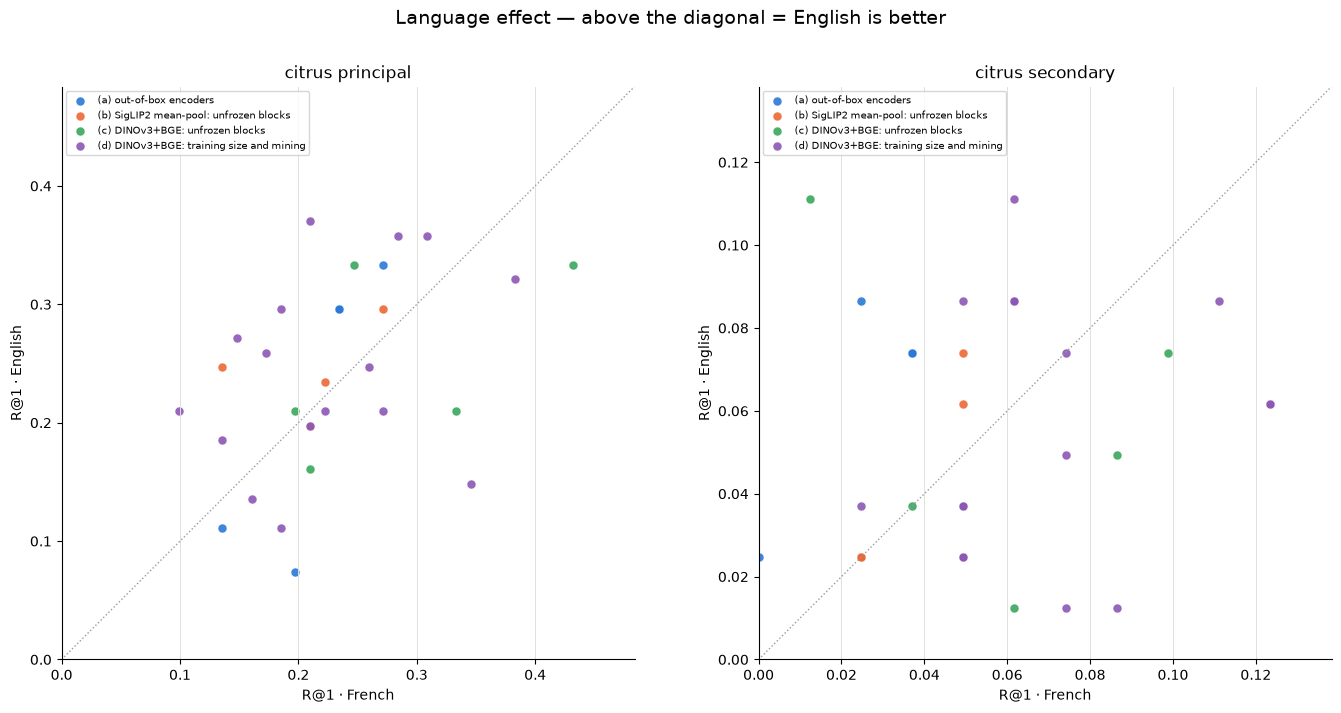

In [25]:
# --- citrus_language_delta.pdf ---------------------------------------------------
# French vs English R@1 per model, one panel per level; the diagonal means "no difference".
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, level in zip(axes, LEVELS):
    block = df_lang[df_lang["level"] == level]
    for key in C0_ORDER:
        b = block[block["c0_group"] == key]
        ax.scatter(b["R@1_fr"], b["R@1_en"], s=42, color=C0_COLOR[key],
                   label=f"({key}) {C0_TITLE[key]}", alpha=0.9,
                   edgecolors="white", linewidths=0.4)
    lim = max(block["R@1_fr"].max(), block["R@1_en"].max(), 0.05) * 1.12
    ax.plot([0, lim], [0, lim], color="#999999", linestyle=":", linewidth=1)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("R@1 · French", fontsize=10)
    ax.set_ylabel("R@1 · English", fontsize=10)
    ax.set_title(f"citrus {level}", fontsize=12)
    ax.legend(fontsize=7, loc="upper left")
    style_ax(ax)
fig.suptitle("Language effect — above the diagonal = English is better", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_fig(fig, "citrus_language_delta.pdf")
plt.show()


## Section 10 — Checks and findings


In [26]:
# --- row-count and coverage checks --------------------------------------------
assert len(df_summary) == len(MODEL_IDS) * len(LEVELS) * len(LANGUAGES)
assert len(df_hier) == len(MODEL_IDS) * len(LANGUAGES)
assert len(df_lang) == len(MODEL_IDS) * len(LEVELS)
assert len(df_stage) == len(MODEL_IDS) * len(LANGUAGES) * (
    POOL_SIZE["principal"] + POOL_SIZE["secondary"])
assert df_stage.groupby(["level", "stage_id"])["support"].nunique().eq(1).all(), \
    "a stage has different support across models"
assert set(df_summary["model_id"]) == set(MODEL_IDS)

print(f"rows: summary {len(df_summary)}, per-stage {len(df_stage)}, "
      f"hierarchy {len(df_hier)}, season {len(df_season)}, language {len(df_lang)}")

# --- auto-generated findings --------------------------------------------------
print()
for level in LEVELS:
    for lang in LANGUAGES:
        block = df_summary[(df_summary["level"] == level) & (df_summary["lang"] == lang)]
        r1 = block.loc[block["R@1"].idxmax()]
        low = block.loc[block["mae"].idxmin()]
        print(f"{level:9s} {lang}: best R@1 {r1['R@1']:.3f} "
              f"({model_label(r1['model_id'])}) | best MAE {low['mae']:5.2f} "
              f"({model_label(low['model_id'])}); chance MAE {low['chance_mae']:.2f}")

print("\nprincipal stages by mean recall (fr):")
print(df_stage[(df_stage["level"] == "principal") & (df_stage["lang"] == "fr")]
      .groupby("stage_id")["recall"].mean().sort_values().round(3).to_string())

print("\nhierarchy (mean over models):")
for lang in LANGUAGES:
    m = df_hier[df_hier["lang"] == lang]
    print(f"  {lang}: sec R@1 {m['sec_R@1'].mean():.3f} | "
          f"given principal correct {m['sec_R@1_given_pri_correct'].mean():.3f} | "
          f"given principal wrong {m['sec_R@1_given_pri_wrong'].mean():.3f}")


rows: summary 120, per-stage 2580, hierarchy 60, season 480, language 60

principal fr: best R@1 0.432 (DINOv3-BGE_8L_2500) | best MAE  1.21 (DINOv3-BGE_8L_2500); chance MAE 3.24
principal en: best R@1 0.370 (DINOv3-BGE_6L_10000) | best MAE  1.77 (SigLIP2-meanpool_out-of-box); chance MAE 3.24
secondary fr: best R@1 0.123 (DINOv3-BGE-mined_6L_5000) | best MAE 18.69 (CLIP-meanpool_out-of-box); chance MAE 31.78
secondary en: best R@1 0.111 (DINOv3-BGE_4L_2500) | best MAE 18.06 (DINOv3-BGE_4L_2500); chance MAE 31.78

principal stages by mean recall (fr):
stage_id
0    0.033
9    0.100
3    0.144
5    0.194
7    0.212
1    0.217
8    0.309
6    0.394

hierarchy (mean over models):
  fr: sec R@1 0.056 | given principal correct 0.102 | given principal wrong 0.044
  en: sec R@1 0.055 | given principal correct 0.082 | given principal wrong 0.046


### Findings (citrus only, from the notebook 33 run)

**Exact secondary stages remain out of reach; the ordinal neighbourhood does not.**
Across the 30 checkpoints, citrus secondary R@1 averages 0.056 fr / 0.055 en, and the best
model reaches 0.123 / 0.111. The best ordinal MAE is 18.7 / 18.1 BBCH units against an
exact chance of 31.8, so the models place a photo much closer than random without naming
the two-digit stage.

**A majority-stage baseline is hard to beat at secondary.** Always predicting the modal
citrus stage (59) gives MAE 19.8 and beats 26 of the 30 checkpoints in each language; only
four checkpoints per language improve on it. At principal the modal stage (5) gives MAE
2.1 and beats 22 of 30. Exact-stage gains should therefore be read against this constant
predictor as well as against uniform chance.

**Principal is where fine-tuning pays.** R@1 is 0.432 fr (`DINOv3-BGE_8L_2500`, MAE 1.21)
and 0.370 en (`DINOv3-BGE_6L_10000`, MAE 1.85) against a chance MAE of 3.24. The
out-of-box SigLIP2 encoder still wins principal-en MAE (1.77), so the gain is not uniform
across languages or architectures.

**Per-stage recall is very uneven.** Mean principal recall (fr) runs from 0.03 at stage 0
(dormancy/bud break) to 0.39 at stage 6; stages 5 and 6 hold 36 of the 81 photos, so most
of the principal score comes from the fruit-development stretch, while dormancy and
senescence are poorly recognised (stage 9 recall 0.10).

**A correct principal helps, but the headroom is small.** Across models, secondary R@1 is
0.102 fr / 0.082 en when the principal top-1 is correct, versus 0.044 / 0.046 when it is
wrong, and the mean sibling rate is 0.25 / 0.24. For the best French secondary model by
R@1 (`DINOv3-BGE-mined_6L_33208`) it is 0.167 given a correct principal against 0.116
given a wrong one. Even in that good case only ~17 % of secondary top-1s are exact, which
is why coarse-to-fine reranking has little headroom unless the candidate set is pruned.

**The error is concentrated early in the season.** For the best French secondary model by
MAE (the zero-shot CLIP mean-pool encoder), MAE by ground-truth principal is
47.7 / 42.5 / 19.7 at principals 0 / 1 / 3, with a bias of +47.7 / +42.5 / +19.7: the
model predicts far too late. Principal 8 is easiest (MAE 6.9), and senescence (9) is
predicted too early (bias −33.2).

**Language is neutral.** French beats English on R@1 for 14/30 models at principal and
13/30 at secondary, with mean deltas of −0.010 and +0.002 — no consistent French
advantage, unlike what per-cell maxima can suggest.


## Section 11 — Hardest and easiest photos and stages

Difficulty is aggregated over **all 30 checkpoints and both language descriptions**, so
each photo or stage is summarised from 60 model × language cells per level.

- **Photo difficulty** — exact top-1 rate, top-3 rate, mean ordinal distance and the
  number of distinct checkpoints that ever get the photo exactly right.
- **Stage difficulty** — support, mean/min/max recall across the 60 cells, mean ordinal
  distance of the photos truly in that stage, and the share of cells with zero recall.
  Secondary supports are only 1–5 photos, so the displayed easiest/hardest lists require
  support ≥ 2 there; the CSV keeps every stage with its support.


03:14:22 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_photo_difficulty.csv (162 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_photo_difficulty.csv (162 rows, 13 columns)


03:14:22 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_stage_difficulty.csv (42 rows)


Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_stage_difficulty.csv (42 rows, 10 columns)

principal · hardest photos (all models, both languages)


,photo,gt_id,exact_rate,top3_rate,mean_distance,model_exact_count
61,73_1,7,0.017,0.250,2.267,1
3,07_1,0,0.033,0.183,4.967,2
6,09_2,0,0.050,0.333,4.033,3
77,91_2,9,0.050,0.183,2.967,3
54,69_1,6,0.050,0.383,2.867,3
5,09_1,0,0.067,0.317,4.267,4


principal · easiest photos


... (10 outputs left out)

,stage_id,support,mean_recall,min_recall,max_recall,mean_distance,share_zero_recall
17,32,2,0.000,0.0,0.000,37.667,1.000
23,57,3,0.000,0.0,0.000,18.133,1.000
22,56,3,0.006,0.0,0.333,21.172,0.983
31,72,3,0.011,0.0,0.333,17.878,0.967
11,07,2,0.017,0.0,1.000,51.333,0.983
14,15,2,0.017,0.0,0.500,42.350,0.967


secondary · easiest stages


,stage_id,support,mean_recall,min_recall,max_recall,mean_distance,share_zero_recall
27,65,5,0.170,0.0,1.000,11.520,0.517
36,83,3,0.161,0.0,1.000,17.383,0.683
39,91,2,0.158,0.0,1.000,29.458,0.767
28,67,3,0.089,0.0,0.667,16.156,0.767
29,69,3,0.089,0.0,1.000,27.617,0.833
34,79,2,0.083,0.0,1.000,16.833,0.850


03:14:23 INFO Wrote /mnt/local_agrifutur/sji/bsv-crossmodalIR/BBCH case study/figures/citrus/citrus_difficulty_extremes.pdf


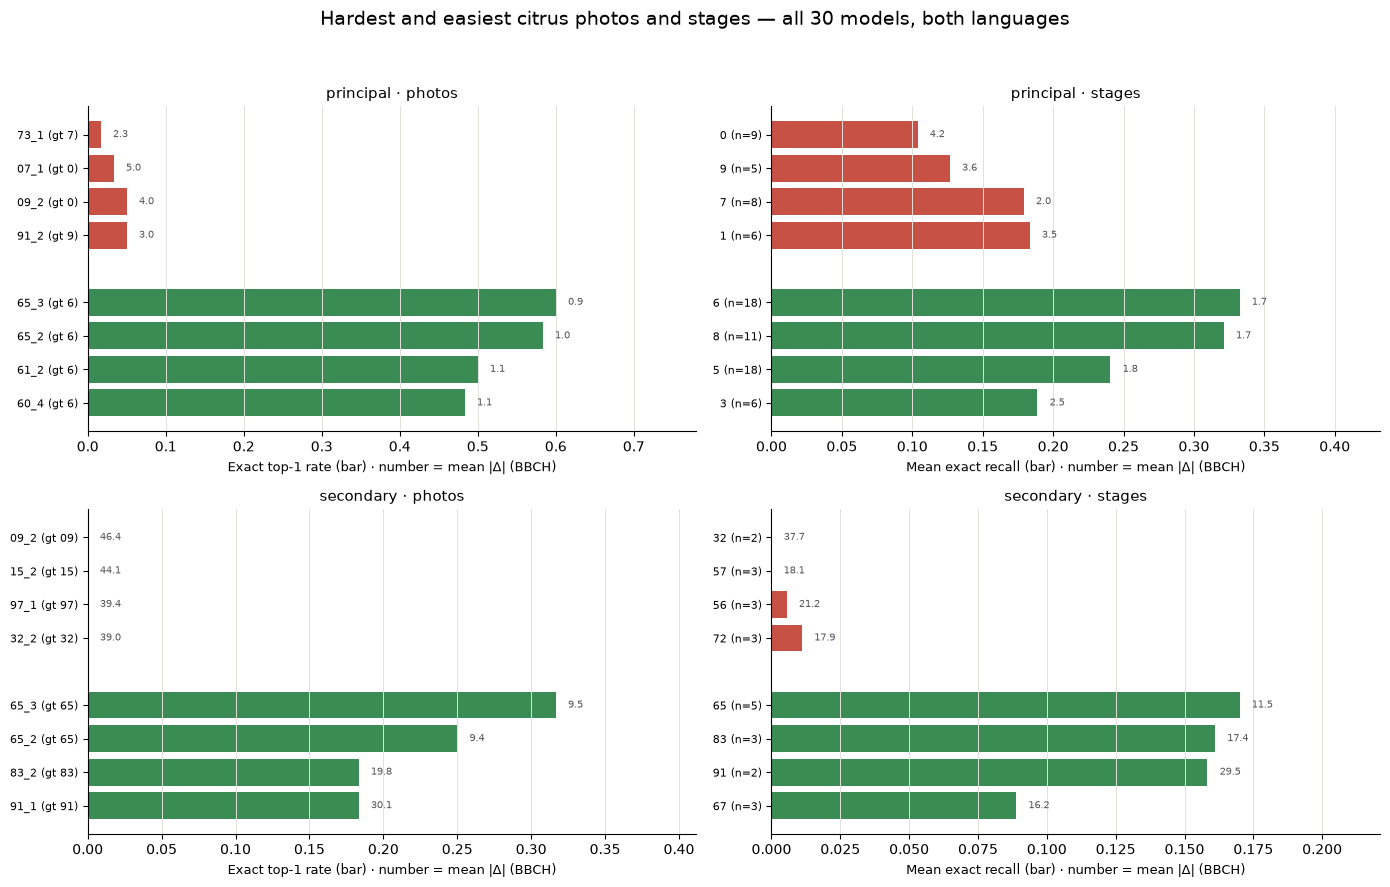

In [27]:
# --- citrus_photo_difficulty.csv / citrus_stage_difficulty.csv ------------------
# Hardest/easiest photos and stages aggregated over all 30 models x 2 languages.
DIFF_MIN_SUPPORT = {"principal": 1, "secondary": 2}


def short_photo_name(name):
    """'citrus#photo_citrus_bbch_73_1.jpeg' -> '73_1'."""
    stem = name.split("citrus#photo_citrus_bbch_")[-1]
    return stem.rsplit(".", 1)[0]


photo_parts = []
for level in LEVELS:
    sub = pred[pred["level"] == level]
    stats = sub.groupby("photo_name").agg(
        gt_id=("gt_id", "first"),
        gt_ordinal=("gt_ordinal", "first"),
        gt_principal=("gt_principal", "first"),
        n_cells=("rank", "size"),
        exact_rate=("rank", lambda s: float((s <= 1).mean())),
        top3_rate=("rank", lambda s: float((s <= 3).mean())),
        mean_distance=("ordinal_distance", "mean"),
        median_distance=("ordinal_distance", "median"),
        mean_rank=("rank", "mean"),
    )
    exact_models = (sub[sub["rank"] <= 1]
                    .groupby("photo_name")["model_id"].nunique()
                    .reindex(stats.index).fillna(0).astype(int))
    stats["model_exact_count"] = exact_models
    stats["level"] = level
    stats["photo"] = [short_photo_name(name) for name in stats.index]
    photo_parts.append(stats.reset_index())

PHOTO_DIFF_COLS = ["level", "photo_name", "photo", "gt_id", "gt_ordinal",
                   "gt_principal", "n_cells", "exact_rate", "top3_rate",
                   "mean_distance", "median_distance", "mean_rank",
                   "model_exact_count"]
df_photo_diff = pd.concat(photo_parts, ignore_index=True)[PHOTO_DIFF_COLS]
assert (df_photo_diff["n_cells"] == len(MODEL_IDS) * len(LANGUAGES)).all()
save_table(df_photo_diff, "citrus_photo_difficulty.csv", preview=0)

stage_cells = df_stage[df_stage["support"] > 0]
df_stage_diff = (stage_cells.groupby(["level", "stage_id"])
                 .agg(support=("support", "first"),
                      mean_recall=("recall", "mean"),
                      min_recall=("recall", "min"),
                      max_recall=("recall", "max"),
                      mean_distance=("mean_distance", "mean"),
                      mean_precision=("precision", "mean"),
                      n_cells=("recall", "size"),
                      share_zero_recall=("recall", lambda s: float((s == 0).mean())))
                 .reset_index())
STAGE_DIFF_COLS = ["level", "stage_id", "support", "mean_recall", "min_recall",
                   "max_recall", "mean_distance", "mean_precision", "n_cells",
                   "share_zero_recall"]
df_stage_diff = df_stage_diff[STAGE_DIFF_COLS]
save_table(df_stage_diff, "citrus_stage_difficulty.csv", preview=0)

photo_cols = ["photo", "gt_id", "exact_rate", "top3_rate", "mean_distance",
              "model_exact_count"]
stage_cols = ["stage_id", "support", "mean_recall", "min_recall", "max_recall",
              "mean_distance", "share_zero_recall"]
for level in LEVELS:
    p = df_photo_diff[df_photo_diff["level"] == level]
    hard = p.sort_values(["exact_rate", "mean_distance"],
                         ascending=[True, False]).head(6)
    easy = p.sort_values(["exact_rate", "mean_distance"],
                         ascending=[False, True]).head(6)
    print(f"\n{level} · hardest photos (all models, both languages)")
    display(hard[photo_cols].round(3))
    print(f"{level} · easiest photos")
    display(easy[photo_cols].round(3))

    s = df_stage_diff[(df_stage_diff["level"] == level)
                      & (df_stage_diff["support"] >= DIFF_MIN_SUPPORT[level])]
    hard_s = s.sort_values(["mean_recall", "mean_distance"],
                           ascending=[True, False]).head(6)
    easy_s = s.sort_values(["mean_recall", "mean_distance"],
                           ascending=[False, True]).head(6)
    print(f"{level} · hardest stages (support >= {DIFF_MIN_SUPPORT[level]})")
    display(hard_s[stage_cols].round(3))
    print(f"{level} · easiest stages")
    display(easy_s[stage_cols].round(3))

# --- citrus_difficulty_extremes.pdf ------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for i, level in enumerate(LEVELS):
    p = df_photo_diff[df_photo_diff["level"] == level]
    hard = p.sort_values(["exact_rate", "mean_distance"],
                         ascending=[True, False]).head(4)
    easy = p.sort_values(["exact_rate", "mean_distance"],
                         ascending=[False, True]).head(4)

    combo_p = pd.concat([hard.assign(extreme="hardest"),
                         easy.assign(extreme="easiest")])
    y_p = np.concatenate([np.arange(len(hard)),
                          np.arange(len(hard) + 1, len(hard) + 1 + len(easy))])
    colors_p = (["#C0392B"] * len(hard)) + (["#1E7B3C"] * len(easy))
    ax = axes[i, 0]
    ax.barh(y_p, combo_p["exact_rate"], color=colors_p, alpha=0.88)
    ax.set_yticks(y_p)
    ax.set_yticklabels([f"{row.photo} (gt {row.gt_id})"
                        for _, row in combo_p.iterrows()], fontsize=8)
    ax.invert_yaxis()
    xmax_p = max(float(combo_p["exact_rate"].max()) * 1.30, 0.05)
    ax.set_xlim(0, xmax_p)
    for yi, (_, row) in zip(y_p, combo_p.iterrows()):
        ax.text(row["exact_rate"] + xmax_p * 0.02, yi,
                f"{row['mean_distance']:.1f}", va="center", fontsize=7,
                color="#555555")
    ax.set_xlabel("Exact top-1 rate (bar) · number = mean |Δ| (BBCH)", fontsize=9)
    ax.set_title(f"{level} · photos", fontsize=11)
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    s = df_stage_diff[(df_stage_diff["level"] == level)
                      & (df_stage_diff["support"] >= DIFF_MIN_SUPPORT[level])]
    hard_s = s.sort_values(["mean_recall", "mean_distance"],
                           ascending=[True, False]).head(4)
    easy_s = s.sort_values(["mean_recall", "mean_distance"],
                           ascending=[False, True]).head(4)
    combo = pd.concat([hard_s.assign(extreme="hardest"),
                       easy_s.assign(extreme="easiest")])
    y = np.concatenate([np.arange(len(hard_s)),
                        np.arange(len(hard_s) + 1, len(hard_s) + 1 + len(easy_s))])
    colors = (["#C0392B"] * len(hard_s)) + (["#1E7B3C"] * len(easy_s))
    ax = axes[i, 1]
    ax.barh(y, combo["mean_recall"], color=colors, alpha=0.88)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{row.stage_id} (n={int(row.support)})"
                        for _, row in combo.iterrows()], fontsize=8)
    ax.invert_yaxis()
    xmax = max(float(combo["mean_recall"].max()) * 1.30, 0.05)
    ax.set_xlim(0, xmax)
    for yi, (_, row) in zip(y, combo.iterrows()):
        ax.text(row["mean_recall"] + xmax * 0.02, yi, f"{row['mean_distance']:.1f}",
                va="center", fontsize=7, color="#555555")
    ax.set_xlabel("Mean exact recall (bar) · number = mean |Δ| (BBCH)", fontsize=9)
    ax.set_title(f"{level} · stages", fontsize=11)
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Hardest and easiest citrus photos and stages — all 30 models, both languages",
             fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "citrus_difficulty_extremes.pdf")
plt.show()
